# Прогнозирование температуры звезды

<div style="background-color: white; border: 1px solid #FC2626; border-radius: 1px; padding: 15px 25px; display: inline-block; color: black;">
    
## <span style="color:#1ABBFF"> Описание проекта

---
    
**з а к а з ч и к:**
    
Обсерватория `«Небо на ладони»`.

**ц е л ь:**
    
Разработать нейросеть для определения температуры на поверхности обнаруженных звёзд на основе их наблюдаемых характеристик.

**з а д а ч и:**

<span style="color:#AAF0F0">


**1.** <span style="color:black">Провести исследовательский анализ данных;

**2.** <span style="color:black">Подготовить данные для обучения;

**3.** <span style="color:black">Построить базовую нейронную сеть;

**4.** <span style="color:black">Улучшить нейронную сеть;

**5.** <span style="color:black">Сравнить модели по ключевым критериям:
- <span style="color:black">качество модели (RMSE);
- <span style="color:black">скорость обучения;
- <span style="color:black">стабильность предсказаний.

**6.** <span style="color:black">Выбрать лучшую модель, проверить её качество на тестовой выборке и сделать выводы.

---

    
<span style="color:#1ABBFF"> ОПИСАНИЕ ДАННЫХ

<span style="color:#E06EC7">

**п р и з н а к и**

- <span style="color:black"> `L/Lo` — относительная светимость звезды (относительно Солнца);
- <span style="color:black"> `R/Ro` — относительный радиус звезды (относительно радиуса Солнца);
- <span style="color:black"> `Mv` — абсолютная звёздная величина (физическая яркость);
- <span style="color:black"> `Color` — звёздный цвет (white, red, blue, yellow, yellow-orange и др.);
- <span style="color:black"> `Star type` — тип звезды (0–5: коричневый карлик, красный карлик, белый карлик, главная последовательность, сверхгигант, гипергигант).

**ц е л е в о й**

- <span style="color:black"> `T(K)` — абсолютная температура на поверхности звезды (в Кельвинах).

---

<span style="color:#AAF0F0">

<span style="color:#1ABBFF"> КРИТЕРИИ УСПЕХА

- <span style="color:black"> `RMSE < 4500 Кельвинов`

- <span style="color:black"> `Нейросеть не переобучена` (ошибка на валидации и обучении близки)

- <span style="color:black">`График "Факт — Прогноз"` показывает линейную зависимость без сильного разброса

---

</div>

## <span style="color:#1ABBFF"> Импорты

In [1]:
!pip install phik -q

In [2]:
# Импорты

# 1. Системные и утилиты
import random
import time
import warnings
from collections import defaultdict

# 2. NumPy и Pandas
import numpy as np
import pandas as pd

# 3. Статистика
from scipy.stats import shapiro, normaltest

# 4. Визуализация
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, ListedColormap

# 5. Статистика и корреляция
from phik import phik_matrix

# 6. Scikit-learn (масштабирование, разделение данных, метрики)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, FunctionTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.compose import ColumnTransformer

# 7. PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# 8. Дополнительно для перебора гиперпараметров
from itertools import product

#### <span style="color:#FC9126">Функция. Фиксация `random seed` для воспроизводимости

In [3]:
def set_seed(seed=42):
    '''
    Функция фиксирует случайность в Python, NumPy и PyTorch, чтобы результаты обучения нейросети были воспроизводимыми
    '''
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

SEED = 42
set_seed(SEED)

## <span style="color:#1ABBFF"> Загрузка и изучение данных

####  <span style="color:#FC9126">Функция. Пропущенные значения

In [4]:
def get_missing_info(df):
    ''' Возвращает DataFrame с информацией о пропущенных значениях'''
    missing_values = df.isnull().sum()
    total_rows = df.shape[0]
    columns_with_missing = missing_values[missing_values > 0]
    
    if len(columns_with_missing) == 0:
        return None
    
    missing_df = pd.DataFrame({
                               'Столбец': columns_with_missing.index,
                               'Кол-во пропусков': columns_with_missing.values,
                               '% пропусков': (columns_with_missing.values / total_rows * 100).round(2)
                              })
    return missing_df

#### <span style="color:#FC9126">Функция. Общая информация и Первые строки

In [5]:
def head_and_info_display(df, n=5, show_shape=True, show_dtypes=True):
    '''
    Параметры:
    df - DataFrame для анализа
    n - Количество строк
    '''
    print('~' * 23)
    print('ИНФОРМАЦИЯ О ДАТАФРЕЙМЕ')
    print('~' * 23)
    
    # 1. Размер данных
    if show_shape:
        print(f'Форма данных: {df.shape[0]} строк, {df.shape[1]} столбцов')

    # 2. Названия столбцов
    print(f'\nНАЗВАНИЯ СТОЛБЦОВ ({len(df.columns)} шт.):')
    print('-' * 28)
    for i, col in enumerate(df.columns, 1):
        print(f'{i:2}. {col}')
    
    # 3. Первые n строк
    print(f'\nПервые {n} строк:')
    print('-' * 15)
    display(df.head(n))
    
    # 4. Общая информация
    if show_dtypes:
        print(f'\nОбщая информация:')
        print('-' * 17)
        df.info()
    
    # 5. Пропущенные значения (используем отдельную функцию get_missing_info)
    print(f'\nПРОПУЩЕННЫЕ ЗНАЧЕНИЯ:')
    print('-' * 20)
    
    missing_df = get_missing_info(df)
    
    if missing_df is None:
        print('   • Пропущенных значений нет')
    else:
        print(f'Столбцы с пропущенными значениями ({len(missing_df)} из {df.shape[1]}):')
        display(missing_df)
        
        total_missing = df.isnull().sum().sum()
        total_rows = df.shape[0]
        print(f'   • Всего пропусков в датафрейме: {total_missing}')
        print(f'   • Доля пропущенных значений: {(total_missing / (total_rows * df.shape[1]) * 100).round(2)}%')
       
    # 6. Дубликаты строк
    print(f'\nПРОВЕРКА ЯВНЫХ ДУБЛИКАТОВ:')
    print('-' * 26)
    duplicates_count = df.duplicated().sum()
    total_rows = df.shape[0]
    if duplicates_count == 0:
        print('   • Дубликатов строк нет')
    else:
        print(f'   • Найдено {duplicates_count} дубликатов строк ({duplicates_count/total_rows*100:.2f}% данных)') 
        
    # 7. Статистика
    print(f'\nСТАТИСТИКА:')
    print('-' * 11)
    display(df.describe())

### Загрузка данных

In [6]:
df = pd.read_csv('/datasets/6_class.csv')

# Выведем информацию о датафрейме df
head_and_info_display(df)

~~~~~~~~~~~~~~~~~~~~~~~
ИНФОРМАЦИЯ О ДАТАФРЕЙМЕ
~~~~~~~~~~~~~~~~~~~~~~~
Форма данных: 240 строк, 7 столбцов

НАЗВАНИЯ СТОЛБЦОВ (7 шт.):
----------------------------
 1. Unnamed: 0
 2. Temperature (K)
 3. Luminosity(L/Lo)
 4. Radius(R/Ro)
 5. Absolute magnitude(Mv)
 6. Star type
 7. Star color

Первые 5 строк:
---------------


,Unnamed: 0,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type,Star color
0,0,3068,0.002400,0.1700,16.12,0,Red
1,1,3042,0.000500,0.1542,16.60,0,Red
2,2,2600,0.000300,0.1020,18.70,0,Red
3,3,2800,0.000200,0.1600,16.65,0,Red
4,4,1939,0.000138,0.1030,20.06,0,Red



Общая информация:
-----------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              240 non-null    int64  
 1   Temperature (K)         240 non-null    int64  
 2   Luminosity(L/Lo)        240 non-null    float64
 3   Radius(R/Ro)            240 non-null    float64
 4   Absolute magnitude(Mv)  240 non-null    float64
 5   Star type               240 non-null    int64  
 6   Star color              240 non-null    object 
dtypes: float64(3), int64(3), object(1)
memory usage: 13.2+ KB

ПРОПУЩЕННЫЕ ЗНАЧЕНИЯ:
--------------------
   • Пропущенных значений нет

ПРОВЕРКА ЯВНЫХ ДУБЛИКАТОВ:
--------------------------
   • Дубликатов строк нет

СТАТИСТИКА:
-----------


,Unnamed: 0,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type
count,240.00000,240.000000,240.000000,240.000000,240.000000,240.000000
mean,119.50000,10497.462500,107188.361635,237.157781,4.382396,2.500000
std,69.42622,9552.425037,179432.244940,517.155763,10.532512,1.711394
min,0.00000,1939.000000,0.000080,0.008400,-11.920000,0.000000
25%,59.75000,3344.250000,0.000865,0.102750,-6.232500,1.000000
50%,119.50000,5776.000000,0.070500,0.762500,8.313000,2.500000
75%,179.25000,15055.500000,198050.000000,42.750000,13.697500,4.000000
max,239.00000,40000.000000,849420.000000,1948.500000,20.060000,5.000000


<div style="background-color: #FCFCFC; border: 1px solid #FC2626; border-radius: 5px; padding: 15px 25px; display: inline-block; color: black;">


### в ы в о д

---
<span style="color:#AAF0F0">
    
В ДАННОМ РАЗДЕЛЕ МЫ ЗНАКОМИЛИСЬ С ДАННЫМИ И ПЕРВИЧНО ИХ ОЦЕНИЛИ.
    
**1.** <span style="color:black"> `Форма данных`: 240 строк, 7 столбцов;
  
**2.** <span style="color:black"> `Пропущенные значения и явные дубликаты не обнаружены, типы данных указаны верно`;
    

---

ДАЛЕЕ

<span style="color:black"> *Проведем подготовку данных:*

- <span style="color:black"> Удалим столбец `Unnamed: 0` так как он дублирует индексы;
- <span style="color:black"> А так же `исправим названия столбцов`;
- <span style="color:black"> Изучим данные поближе.

## <span style="color:#1ABBFF"> Предобработка и анализ данных

### Предоработка

In [7]:
# Уберем столбец "Unnamed: 0" так как он дублирует индексы
df.drop('Unnamed: 0', axis=1, inplace=True)
df = df.reset_index(drop=True)

In [8]:
# Изменим название колонок
df = df.rename(
                columns={
                        'Temperature (K)': 'temperature',
                        'Luminosity(L/Lo)': 'luminosity',
                        'Radius(R/Ro)': 'radius',
                        'Absolute magnitude(Mv)': 'abs_magnitude',
                        'Star type': 'star_type',
                        'Star color': 'star_color'
                         }
               )
# Проверочка
df.columns

Index(['temperature', 'luminosity', 'radius', 'abs_magnitude', 'star_type',
       'star_color'],
      dtype='object')

<div style="border-left: 2px solid #FCDC26; padding-left: 15px; margin: 15px 0;">

СПЕКТРАЛЬНАЯ КЛАССИФИКАЦИЯ ЗВЁЗД

*Согласно принятым стандартам классификация звёзд по цвету предполагает деление на `7 типов`:*

- <span style="color:#FC2626">**Red** `[2000-3500 K]`
- <span style="color:#FC9126">**Orange** `[3500-5000 K]`
- <span style="color:#FCDC26">**Yellow** `[5000-6000 K]`
- <span style="color:#FAFF85">**Yellow-White** `[6000-7500 K]`
- <span style="color:#E8E8E8">**White** `[7500-10000 K]`
- <span style="color:#AAF0F0">**Blue-White** `[10000-30000 K]`
- <span style="color:#1ABBFF">**Blue** `[30000-60000 K]`
    
 


In [9]:
# Выведем уникальное значение Цвета и его температуры (списком, отсортированным по возрастанию)
print('ЦВЕТ -> ТЕМПЕРАТУРА (отсортировано по температуре)')
print('-' * 55)

for color in sorted(df['star_color'].unique()):
    temps = sorted(df[df['star_color'] == color]['temperature'].tolist())
    print(f'{color}: {temps}')

ЦВЕТ -> ТЕМПЕРАТУРА (отсортировано по температуре)
-------------------------------------------------------
Blue: [5752, 7282, 8927, 9373, 9383, 9892, 10930, 11096, 11567, 12675, 12749, 12893, 13340, 14245, 14982, 15680, 16787, 16790, 17120, 17383, 17920, 18000, 18290, 18340, 18734, 19360, 19920, 19923, 21020, 21738, 23000, 23092, 23095, 23440, 23678, 24020, 24345, 24630, 25390, 26000, 26373, 30839, 32460, 32489, 33300, 33421, 33750, 34190, 36108, 37800, 37882, 38234, 38940, 39000, 40000]
Blue : [19860]
Blue White: [9675, 10980, 12010, 12984, 13420, 14100, 14520, 16500, 17200, 25000]
Blue white: [8570, 8924, 12912]
Blue white : [11900]
Blue-White: [8945]
Blue-white: [9030, 9320, 10012, 11000, 11250, 12098, 12100, 13023, 13089, 14060, 15276, 16390, 17140, 19400, 20120, 21904, 22012, 22350, 24145, 24490, 25070, 26140, 27739, 28700, 29560, 30000]
Orange: [3749, 4287]
Orange-Red: [5112]
Pale yellow orange: [7230]
Red: [1939, 2600, 2600, 2621, 2637, 2650, 2650, 2700, 2731, 2774, 2778, 2799, 

<div style="border-left: 2px solid #FCDC26; padding-left: 15px; margin: 15px 0;">
    
к о м м е н т а р и й
    
**1.**  На первый взгляд, в данных встречаются неявные дубликаты [пример: Blue White и Blue white], но при детальном анализе видно, что их температурные значения не согласуются со спектральной классификацией звёзд.

**2.** Поэтому мы исключим этот признак и сформируем новый, опираясь на температуру в соответствии со спектральными нормами.

</div>

In [10]:
bins = [0, 3500, 5000, 6000, 7500, 10000, 30000, 100000]
labels = ['Red', 'Orange', 'Yellow', 'Yellow-White', 'White', 'Blue-White', 'Blue']
df['color_by_temp'] = pd.cut(df['temperature'], bins=bins, labels=labels, right=True)

In [11]:
print("-" * 60)
print("СТАРОЕ РАСПРЕДЕЛЕНИЕ ПО ЦВЕТАМ")
print("-" * 60)
print(df['star_color'].value_counts())

print("-" * 60)
print("НОВОЕ РАСПРЕДЕЛЕНИЕ ПО ЦВЕТАМ (НА ОСНОВЕ ТЕМПЕРАТУРЫ)")
print("-" * 60)
print(df['color_by_temp'].value_counts().sort_index())

print("-" * 60)
print("ПРИМЕР СТРОК С ИСПРАВЛЕННЫМ КЛАССОМ:")
print("-" * 60)
dif = df[df['color_by_temp'] != df['star_color']]
display(dif.head())

------------------------------------------------------------
СТАРОЕ РАСПРЕДЕЛЕНИЕ ПО ЦВЕТАМ
------------------------------------------------------------
Red                   112
Blue                   55
Blue-white             26
Blue White             10
yellow-white            8
White                   7
Blue white              3
Yellowish White         3
white                   3
Orange                  2
yellowish               2
Whitish                 2
Pale yellow orange      1
Orange-Red              1
Blue-White              1
Yellowish               1
Blue                    1
White-Yellow            1
Blue white              1
Name: star_color, dtype: int64
------------------------------------------------------------
НОВОЕ РАСПРЕДЕЛЕНИЕ ПО ЦВЕТАМ (НА ОСНОВЕ ТЕМПЕРАТУРЫ)
------------------------------------------------------------
Red             76
Orange          40
Yellow           6
Yellow-White     7
White           21
Blue-White      76
Blue            14
Name: color_b

,temperature,luminosity,radius,abs_magnitude,star_type,star_color,color_by_temp
10,3600,0.00290,0.5100,10.69,1,Red,Orange
13,3628,0.00550,0.3930,10.48,1,Red,Orange
17,3692,0.00367,0.4700,10.80,1,Red,Orange
20,25000,0.05600,0.0084,10.58,2,Blue White,Blue-White
22,7220,0.00017,0.0110,14.23,2,White,Yellow-White


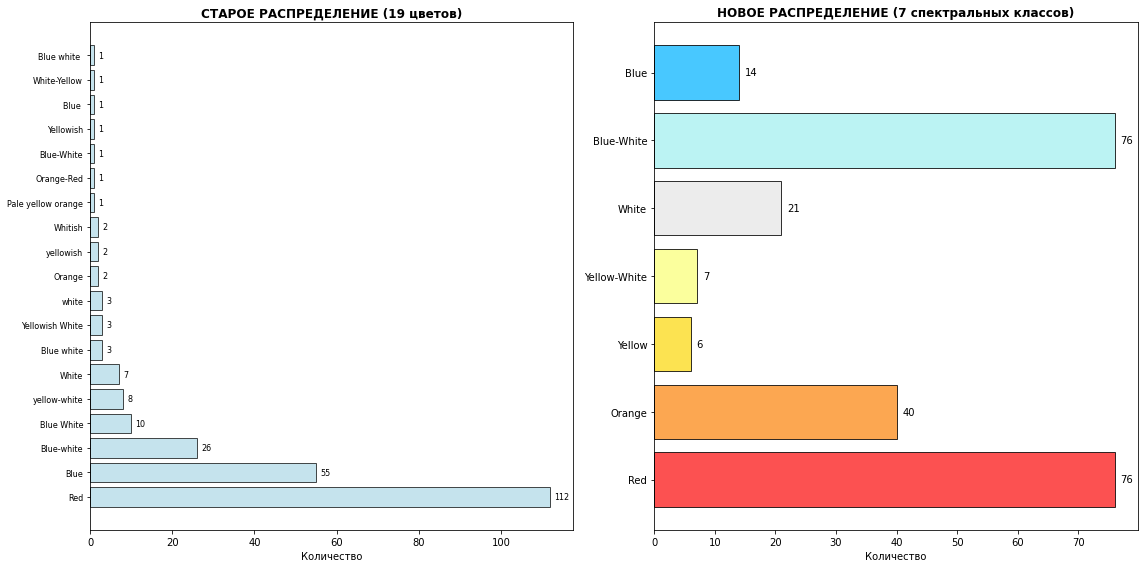

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

# Старое распределение
old_all = df['star_color'].value_counts()
bars1 = ax1.barh(range(len(old_all)), old_all.values, color='lightblue', edgecolor='black', alpha=0.7)
ax1.set_yticks(range(len(old_all)))
ax1.set_yticklabels(old_all.index, fontsize=8)
ax1.set_title('СТАРОЕ РАСПРЕДЕЛЕНИЕ (19 цветов)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Количество')
# Подписи
for i, (bar, v) in enumerate(zip(bars1, old_all.values)):
    ax1.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2, 
             str(v), va='center', fontsize=8)

# Новое распределение
new_dist = df['color_by_temp'].value_counts().sort_index()
colors = ['#FC2626', '#FC9126', '#FCDC26', '#FAFF85', '#E8E8E8', '#AAF0F0', '#1ABBFF']
bars2 = ax2.barh(new_dist.index, new_dist.values, color=colors, edgecolor='black', alpha=0.8)
ax2.set_title('НОВОЕ РАСПРЕДЕЛЕНИЕ (7 спектральных классов)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Количество')
# Подписи 
for bar, v in zip(bars2, new_dist.values):
    ax2.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2, 
             str(v), va='center', fontsize=10)

plt.tight_layout()
plt.show()

In [13]:
# Заменяем старый столбец новым
df['star_color'] = df['color_by_temp'].astype('object')

# Удаляем временный столбец color_by_temp
df.drop('color_by_temp', axis=1, inplace=True)

# Сбрасываем индекс
df = df.reset_index(drop=True)
# Проверяем
head_and_info_display(df)

~~~~~~~~~~~~~~~~~~~~~~~
ИНФОРМАЦИЯ О ДАТАФРЕЙМЕ
~~~~~~~~~~~~~~~~~~~~~~~
Форма данных: 240 строк, 6 столбцов

НАЗВАНИЯ СТОЛБЦОВ (6 шт.):
----------------------------
 1. temperature
 2. luminosity
 3. radius
 4. abs_magnitude
 5. star_type
 6. star_color

Первые 5 строк:
---------------


,temperature,luminosity,radius,abs_magnitude,star_type,star_color
0,3068,0.002400,0.1700,16.12,0,Red
1,3042,0.000500,0.1542,16.60,0,Red
2,2600,0.000300,0.1020,18.70,0,Red
3,2800,0.000200,0.1600,16.65,0,Red
4,1939,0.000138,0.1030,20.06,0,Red



Общая информация:
-----------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   temperature    240 non-null    int64  
 1   luminosity     240 non-null    float64
 2   radius         240 non-null    float64
 3   abs_magnitude  240 non-null    float64
 4   star_type      240 non-null    int64  
 5   star_color     240 non-null    object 
dtypes: float64(3), int64(2), object(1)
memory usage: 11.4+ KB

ПРОПУЩЕННЫЕ ЗНАЧЕНИЯ:
--------------------
   • Пропущенных значений нет

ПРОВЕРКА ЯВНЫХ ДУБЛИКАТОВ:
--------------------------
   • Дубликатов строк нет

СТАТИСТИКА:
-----------


,temperature,luminosity,radius,abs_magnitude,star_type
count,240.000000,240.000000,240.000000,240.000000,240.000000
mean,10497.462500,107188.361635,237.157781,4.382396,2.500000
std,9552.425037,179432.244940,517.155763,10.532512,1.711394
min,1939.000000,0.000080,0.008400,-11.920000,0.000000
25%,3344.250000,0.000865,0.102750,-6.232500,1.000000
50%,5776.000000,0.070500,0.762500,8.313000,2.500000
75%,15055.500000,198050.000000,42.750000,13.697500,4.000000
max,40000.000000,849420.000000,1948.500000,20.060000,5.000000


<div style="border-left: 2px solid #FCDC26; padding-left: 15px; margin: 15px 0;"> 


### промежуточный вывод

---

1. ОЧИСТКА ДАННЫХ

| д е й с т в и е | р е з у л ь т а т |
|----------|-----------|
| Удалён столбец `Unnamed: 0` | Дублировал индекс |
| Переименованы столбцы | Удобные короткие названия |
| Сброшен индекс | Нумерация с 0 до 239 |

**и т о г:** 240 строк, 6 столбцов, без пропусков и дубликатов

---

2. АНАЛИЗ ЦВЕТОВОЙ КЛАССИФИКАЦИИ

**п р о б л е м а:** 19 уникальных названий цветов при реальных 7 спектральных классах

**п р и м е р ы:**
- `Blue`, `Blue `, `Blue White`, `Blue white`, `Blue-white`, `Blue-White`

**в ы в о д:** Температуры не соответствуют спектральной классификации

---

3. СОЗДАНИЕ НОВОГО ЦВЕТОВОГО ПРИЗНАКА

**р е ш е н и е:** Заменили исходный цвет на спектральный класс по температуре

| Исходный цвет | Было | Стало (новый цвет) | Причина |
|---------------|------|--------------------|---------|
| Red | 112 | 76 Red, 35 Orange, 1 Yellow-White | 36 звезд оказались горячее спектрального класса Red |
| Blue (все вариации) | 107 | 14 Blue, 76 Blue-White, 17 White | 93 звезды оказались холоднее спектрального класса Blue |
| Orange | 2 | 2 Orange | без изменений |
| Orange-Red | 1 | 1 Yellow | звезда оказалась горячее |
| Yellow | 1 | 1 Yellow | без изменений |
| White (все вариации) | 17 | 5 White, 7 Yellow-White, 5 Blue-White | распределились по трем классам |
    
---

4. ИТОГОВЫЙ ДАТАФРЕЙМ

**с т о л б ц ы (6 шт.):**
    
- `temperature` — температура в K **(целевой признак)**
- `luminosity` — светимость
- `radius` — радиус
- `abs_magnitude` — абсолютная звёздная величина
- `star_type` — тип звезды (0-5)
- `star_color` — цвет по спектральной классификации

**р а з м е р:** `240 строк, 6 столбцов; пропусков и дубликатов не обнаружено.`

Можно приступать к исследовательскому анализу данных.
    
---

### Исследование данных

<div style="border-left: 4px solid #FCDC26; padding-left: 15px; margin: 15px 0;"> 

### количественные признаки
 
- **`temperature`**
    
- **`luminosity`**  `[нужен логарифм: Разброс в миллиарды раз -> 0.00008 - 849420]`

- **`radius`** `[нужен логарифм: Разброс в сотни тысяч раз	-> 0.008 - 1948]`
    
- **`abs_magnitude`**
    
---
    
к о м м е н т а р и й
    
**Без логарифма**
    
На графике все маленькие значения (0.00008 - 1) сожмутся в одну точку у нуля, а огромные значения (100000+) улетят далеко вправо. И мы ничего не увидим.

**С логарифмом:**
    
Логарифм "сжимает" огромный диапазон в удобный для глаз. 
Все значения помещаются на графике от -4 до +6. Разница между числами нагляднее.

---

#### <span style="color:#FC9126">Функция. Диаграмма размаха, гистограмма, диаграмма рассеяния

In [14]:
def plot_quantitative_new(df,column,figsize=(15, 6),palette='Paired',
                          custom_labels=None, discrete_threshold=20, show_diagram=True):
    ''' 
    Ящик с усами и Гистограмма для количественных признаков (звезды)
    + диаграмма рассеяния (опционально)
    
    Параметры:
    -----------
    df : DataFrame - Датафрейм с данными о звездах
    column : str - Название столбца для анализа
    figsize : tuple - размер области построения
    palette : str - Цветовая палитра
    custom_labels : dict - словарь с подписями
    discrete_threshold : int - порог для дискретного признака
    show_diagram : bool - показывать диаграмму рассеивания
    '''
    
    # Словарь с подписями для звезд
    default_labels = {
                      'temperature': ['Температура звезды', 'Температура (K)', 'Количество звезд'],
                      'luminosity': ['Светимость звезды', 'L/Lo (логарифм)', 'Количество звезд'],
                      'radius': ['Радиус звезды', 'R/Ro (логарифм)', 'Количество звезд'],
                      'abs_magnitude': ['Абсолютная звёздная величина', 'Mv', 'Количество звезд'],
                      'star_type': ['Тип звезды', 'Тип (0-5)', 'Количество звезд']
                      }
    
    if custom_labels:
        default_labels.update(custom_labels)
    
    labels_dict = default_labels
    
    if column in labels_dict:
        plot_title, x_label, y_label = labels_dict[column]
    else:
        plot_title = f'Распределение: {column}'
        x_label = column
        y_label = 'Количество звезд'
    
    # Определяем дискретный признак
    unique_values = df[column].nunique()
    is_integer = df[column].dtype in ['int64', 'int32', 'int16', 'int8']
    is_discrete = (unique_values <= discrete_threshold and is_integer) or (unique_values <= 15)
    
    # Определяем количество подграфиков
    if show_diagram:
        # 3 графика: ящик, гистограмма, диаграмма рассеивания
        fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(figsize[0] + 4, figsize[1]))
        ax1, ax2, ax3 = axes
    else:
        fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(figsize[0], figsize[1]))
    
    # Цвет для графиков
    color = sns.color_palette(palette, 1)[0]
    
    # 1. Ящик с усами
    sns.boxplot(data=df, y=column, color=color, ax=ax1)
    ax1.set_title(f'Диаграмма размаха: {plot_title}', fontsize=14)
    ax1.set_ylabel(x_label)
    
    # 2. Гистограмма
    if is_discrete:
        sns.histplot(data=df, x=column, discrete=True, color=color, ax=ax2, shrink=0.8)
        min_val = int(df[column].min())
        max_val = int(df[column].max())
        if (max_val - min_val) <= 30:
            ax2.set_xticks(range(min_val, max_val + 1))
        if unique_values <= 15:
            value_counts = df[column].value_counts().sort_index()
            for val, count in value_counts.items():
                ax2.text(val, count + max(value_counts)*0.02, f'{count}', ha='center', va='bottom', fontsize=9)
    else:
        if column == 'luminosity':
            log_data = np.log10(df[column] + 1e-10)
            sns.histplot(x=log_data, kde=True, color=color, ax=ax2)
            ax2.set_xlabel('log10(L/Lo)')
        elif column == 'radius':
            log_data = np.log10(df[column] + 1e-10)
            sns.histplot(x=log_data, kde=True, color=color, ax=ax2)
            ax2.set_xlabel('log10(R/Ro)')
        else:
            sns.histplot(data=df, x=column, kde=True, color=color, ax=ax2)
    
    ax2.set_title(f'Гистограмма: {plot_title}', fontsize=14)
    ax2.set_xlabel(x_label)
    ax2.set_ylabel(y_label)
    
    median_val = df[column].median()
    if column == 'luminosity':
        ax2.axvline(np.log10(median_val + 1e-10), color='red', linestyle='--', 
                    label=f'Медиана (log10): {np.log10(median_val + 1e-10):.3f}')
    elif column == 'radius':
        ax2.axvline(np.log10(median_val + 1e-10), color='red', linestyle='--', 
                    label=f'Медиана (log10): {np.log10(median_val + 1e-10):.3f}')
    else:
        ax2.axvline(median_val, color='red', linestyle='--', label=f'Медиана: {median_val:.3f}')
    ax2.legend()
    
    # 3. Диаграмма рассеивания
    if show_diagram:
        # Цвета для спектральных классов
        hr_colors = {
                     'Red': '#FC2626',
                     'Orange': '#FC9126',
                     'Yellow': '#FCDC26',
                     'Yellow-White': '#FAFF85',
                     'White': '#E8E8E8',
                     'Blue-White': '#AAF0F0',
                     'Blue': '#1ABBFF'
                      }
        
        # Берем температуру и выбранный признак
        x_data = df['temperature']
        y_data = df[column]
        
        # Цвет точек по спектральному классу
        point_colors = df['star_color'].map(hr_colors).fillna('gray')
        
        ax3.scatter(x_data, y_data, c=point_colors, alpha=0.7, s=50, edgecolors='black', linewidth=0.5)
        
        # Логарифмическая шкала для светимости и радиуса
        if column == 'luminosity':
            ax3.set_yscale('log')
        elif column == 'radius':
            ax3.set_yscale('log')
        
        # Обратная шкала по X (температура уменьшается слева направо)
        ax3.invert_xaxis()
        
        ax3.set_xlabel('Температура (K)', fontsize=12)
        ax3.set_ylabel(x_label, fontsize=12)
        ax3.set_title('Диаграмма рассеяния', fontsize=14, fontweight='bold')
        ax3.grid(True, alpha=0.3)
        
        # Легенда с цветами
        from matplotlib.patches import Patch
        legend_elements = [Patch(facecolor=color, edgecolor='black', label=label) 
                          for label, color in hr_colors.items() if label in df['star_color'].unique()]
        ax3.legend(handles=legend_elements, title='Спектральный класс', loc='best', fontsize=8)
    
    plt.tight_layout()
    plt.show()
    
    # Вывод статистики
    print(f"Статистика для '{plot_title}':")
    print('-' * 50)
    stats = df[column].describe()
    print(f"Тип данных: {'Дискретный' if is_discrete else 'Непрерывный'}")
    print(f"Уникальных значений: {unique_values}")
    print(f"Количество звезд: {stats['count']:.0f}")
    print(f"Среднее: {stats['mean']:.3f}")
    print(f"Медиана: {stats['50%']:.3f}")
    print(f"Минимум: {stats['min']:.6f}")
    print(f"Максимум: {stats['max']:.3f}")
    
    # Проверка на нормальность
    if len(df[column].dropna()) >= 3:
        print(f"\nПроверка на нормальность распределения (α=0.05):")
        print('-' * 50)
        data = df[column].dropna()
        if column == 'luminosity':
            data = np.log10(data + 1e-10)
        elif column == 'radius':
            data = np.log10(data + 1e-10)
        
        if len(data) <= 5000:
            from scipy.stats import shapiro
            shapiro_stat, shapiro_p = shapiro(data)
            print(f"Критерий Шапиро-Уилка: p-value = {shapiro_p:.4f}")
        
        try:
            from scipy.stats import normaltest
            dagostino_stat, dagostino_p = normaltest(data)
            if dagostino_p > 0.05:
                print('ВЫВОД: распределение соответствует нормальному')
            else:
                print('ВЫВОД: распределение НЕ соответствует нормальному')
        except Exception as e:
            print(f'Ошибка: {e}')

- ### `luminosity`

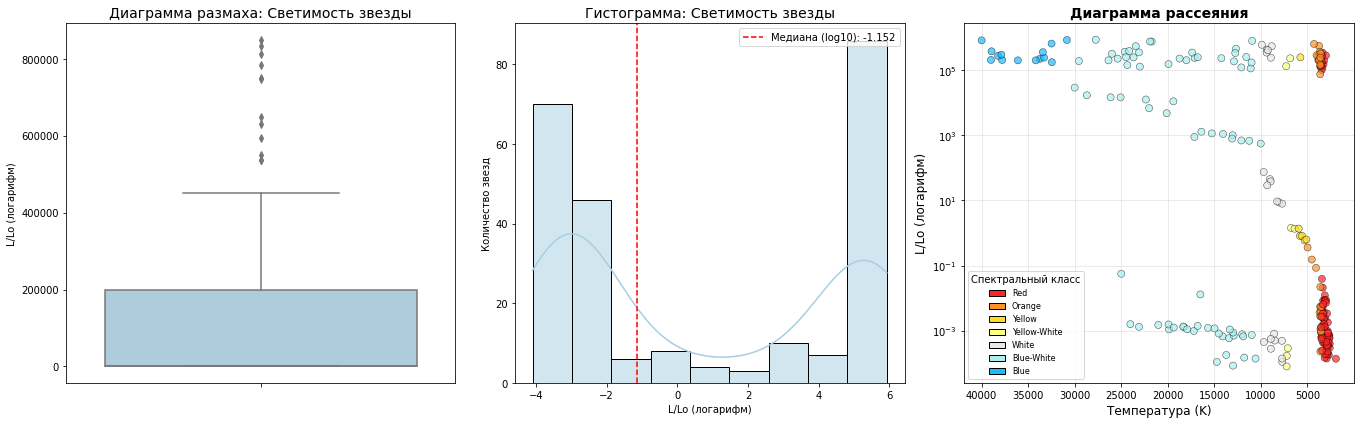

Статистика для 'Светимость звезды':
--------------------------------------------------
Тип данных: Непрерывный
Уникальных значений: 208
Количество звезд: 240
Среднее: 107188.362
Медиана: 0.071
Минимум: 0.000080
Максимум: 849420.000

Проверка на нормальность распределения (α=0.05):
--------------------------------------------------
Критерий Шапиро-Уилка: p-value = 0.0000
ВЫВОД: распределение НЕ соответствует нормальному


In [15]:
plot_quantitative_new(df, 'luminosity')

<div style="border-left: 2px solid #FCDC26; padding-left: 15px; margin: 15px 0;">


### к о м м е н т а р и й
    
---

Перед нами два взаимосвязанных графика, которые вместе дают полную картину распределения звёзд по светимости и температуре.

- **Светимость** (`luminosity`) L/Lo — светимость звезды относительно Солнца.
- **Физический смысл:** Количество энергии, которое звезда излучает за 1 секунду. Показывает мощность звезды.
- Светимость зависит от радиуса звезды (чем больше, тем ярче) и температуры (чем горячее, тем ярче, и в 4-й степени).

---

ДИАГРАММА РАЗМАХА

Этот график показывает распределение светимости, разброс данных и аномалии.

- **Ящик (от ~0 до ~400 000 L/Lo):** Здесь находится 50% всех звёзд.
- **Медиана (0.07 L/Lo или -1.152 в логарифме):** Половина звёзд тусклее, половина — ярче.
- **Усы (до ~450 000 L/Lo):** Нормальный диапазон значений.
- **Выбросы (выше 600 000 L/Lo):** Экстремально яркие звёзды (гиганты и сверхгиганты).

График имеет ярко выраженную **правостороннюю асимметрию**. Большинство звёзд имеют низкую светимость, но есть редкие очень яркие объекты, которые «тянут» среднее значение вверх.

---

ГИСТОГРАММА

- В выборке преобладают либо очень тусклые звёзды (первый пик около -4 по логарифмической шкале), либо очень яркие (второй пик около 6).
- Звёзды со светимостью, близкой к солнечной, встречаются реже — между пиками наблюдается провал.
- Медиана (-1.152 в логарифме) указывает, что половина звёзд тусклее 0.07 светимости Солнца.

---

ДИАГРАММА РАССЕЯНИЯ

- Горячие голубые звёзды расположены слева, холодные красные — справа.
- На диаграмме выделяются: **главная последовательность** (диагональная полоса, где находится большинство звёзд), область **гигантов и сверхгигантов** (вверху) и **белые карлики** (горячие, но тусклые — внизу слева).

---

ИТОГ

Вселенная населена преимущественно тусклыми холодными звёздами (красные карлики), но именно редкие горячие гиганты создают «всплеск» общей светимости, формируя второй пик на гистограмме и выбросы на ящике с усами.

**Вывод для модели:**

- Использовать **логарифмическое преобразование** светимости (разброс слишком велик).

Статистика корректна — данные реальны и готовы к дальнейшей обработке.
    
---

- ### `temperature`

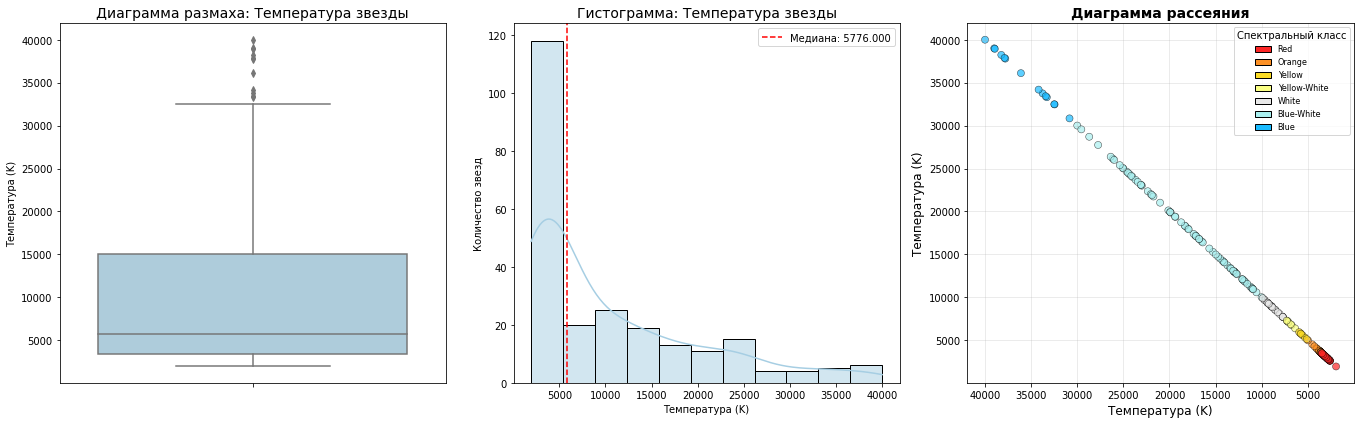

Статистика для 'Температура звезды':
--------------------------------------------------
Тип данных: Непрерывный
Уникальных значений: 228
Количество звезд: 240
Среднее: 10497.462
Медиана: 5776.000
Минимум: 1939.000000
Максимум: 40000.000

Проверка на нормальность распределения (α=0.05):
--------------------------------------------------
Критерий Шапиро-Уилка: p-value = 0.0000
ВЫВОД: распределение НЕ соответствует нормальному


In [16]:
plot_quantitative_new(df, 'temperature')

<div style="border-left: 2px solid #FCDC26; padding-left: 15px; margin: 15px 0;">


### к о м м е н т а р и й
    
---

Перед нами **диаграмма размаха**, **гистограмма**, **диаграмма рассеяния** , которые вместе дают полную картину распределения звёзд по температуре.

- **Температура** (`temperature`) — температура поверхности звезды в Кельвинах (K).
- **Физический смысл:** Мера того, насколько раскалена внешняя оболочка звезды. Определяет цвет звезды и её спектр.
- Чем выше температура, тем короче длина волны света (от красного к синему).

---

ДИАГРАММА РАЗМАХА

- **Ящик (от ~5 000 K до ~15 000 K):** Здесь находится 50% всех звёзд.
- **Медиана (5 776 K):** Половина звёзд холоднее 7 500 K, половина — горячее.
- **Нижний ус (~3 500 K):** Минимальная «обычная» температура.
- **Верхний ус (~33 000 K):** Максимальная «обычная» температура.
- **Выбросы (35 000–40 000 K):** Экстремально горячие звёзды (голубые гиганты).

График имеет **левостороннюю асимметрию** — большинство звёзд холодные, но есть редкие очень горячие объекты, которые «тянут» среднее значение вверх.

---

ГИСТОГРАММА

- В выборке **доминируют холодные звёзды** (пик в области ниже 5 000 K).
- С ростом температуры количество звёзд резко падает.
- Медиана (5 776 K) совпадает с температурой Солнца и делит выборку пополам.
- **Среднее (10 497 K) заметно выше медианы** — это признак правосторонней асимметрии.
- **p-value = 0.0000** (критерий Шапиро-Уилка)  распределение **НЕ соответствует нормальному**.

---

ДИАГРАММА РАССЕЯНИЯ

- Горячие голубые звёзды расположены слева, холодные красные — справа.
- **Главная последовательность** (диагональная полоса) — место рождения большинства звёзд.
- **Гиганты и сверхгиганты** — вверху, **белые карлики** — внизу слева.

---

ИТОГ

- **Тип распределения:** Асимметричное (правостороннее), **не нормальное**.
- **Типичная звезда:** Холодная (температура около **5 776 K**, медиана).
- **Аномалия:** Редкие очень горячие объекты (до 40 000 K) «тянут» среднее до **10 497 K**.

В данных реобладают красные карлики, но визуально ярка благодаря редким горячим гигантам, которые создают «тяжёлый хвост» распределения.

**Вывод для модели:**

- Температуру **не нужно логарифмировать** (разброс ~20 раз).
- Достаточно **StandardScaler** для масштабирования.

Статистика корректна — данные реальны и готовы к дальнейшей обработке.

- ### `radius`

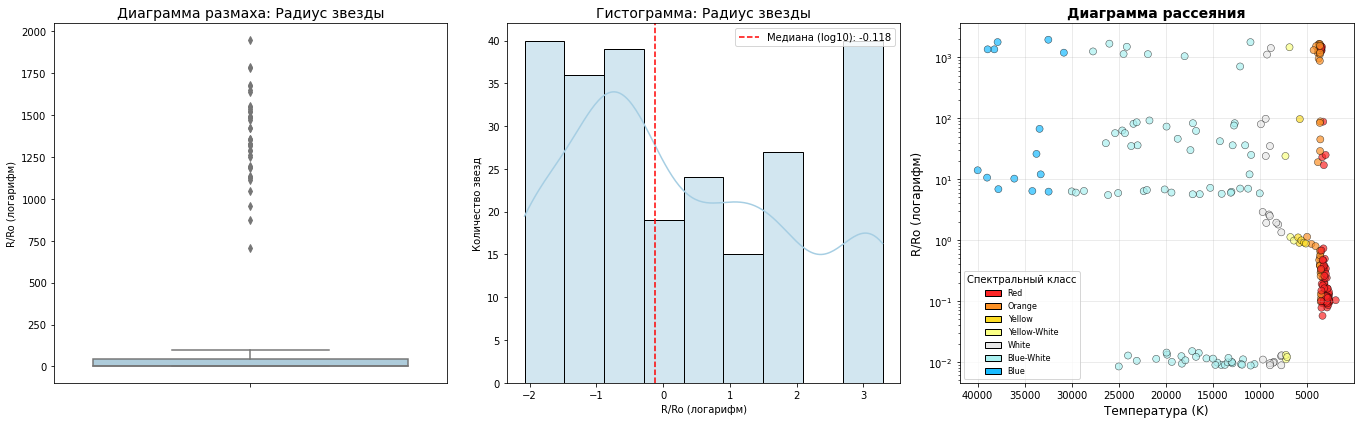

Статистика для 'Радиус звезды':
--------------------------------------------------
Тип данных: Непрерывный
Уникальных значений: 216
Количество звезд: 240
Среднее: 237.158
Медиана: 0.762
Минимум: 0.008400
Максимум: 1948.500

Проверка на нормальность распределения (α=0.05):
--------------------------------------------------
Критерий Шапиро-Уилка: p-value = 0.0000
ВЫВОД: распределение НЕ соответствует нормальному


In [17]:
plot_quantitative_new(df, 'radius')

<div style="border-left: 2px solid #FCDC26; padding-left: 15px; margin: 15px 0;">


### к о м м е н т а р и й
    
---

Перед нами три взаимосвязанных графика, которые вместе дают полную картину распределения звёзд по радиусу.

- **Радиус** (`radius`) R/Ro — радиус звезды относительно радиуса Солнца.
- **Физический смысл:** Размер звезды. Показывает, насколько звезда большая или маленькая.
- **Комментарий:** Белые карлики имеют размер с Землю, но массу как Солнце — они невероятно плотные (чайная ложка весит тонны).

---

ДИАГРАММА РАССЕЯНИЯ

- **Ящик (от ~0.1 до ~10 R/Ro):** Здесь находится 50% всех звёзд.
- **Медиана (~0.76 R/Ro):** Половина звёзд больше, половина — меньше этой отметки. Типичная звезда — карлик (меньше Солнца или чуть больше).
- **Усы:** Верхний ус уходит до ~40 R/Ro, нижний начинается от минимальных значений (~0.01 R/Ro).
- **Выбросы (выше 100 R/Ro):** Экстремально крупные звёзды — красные гиганты и сверхгиганты, радиус которых в сотни и тысячи раз больше солнечного.

График имеет ярко выраженную **правостороннюю асимметрию**. Основная масса звёзд — компактные карлики, но есть редкие гиганты, создающие длинный «хвост» выбросов.

---

ГИСТОГРАММА

- В выборке **преобладают компактные звёзды** (пик в области самых маленьких радиусов, 35–40 объектов).
- С ростом радиуса количество звёзд резко падает — большие объекты встречаются единично.
- Использование логарифмической шкалы позволяет одновременно видеть и карликов, и гигантов, так как разброс огромен.

---

ДИАГРАММА РАССЕЯНИЯ

- **Левый нижний угол:** Плотное скопление — белые и голубые карлики (горячие, но маленькие).
- **Правый верхний угол:** Разрозненные точки — красные гиганты и сверхгиганты (холодные, но огромные).
- **Главная последовательность:** Диагональная полоса, где радиус и температура коррелируют.

---

СТАТИСТИКА

- **Среднее (237 R/Ro) vs Медиана (0.76 R/Ro):** Разница колоссальна. Среднее «тянут» вверх редкие гиганты.
- **Диапазон:** от **0.0084 R/Ro** (белый карлик размером с Землю) до **1948 R/Ro** (сверхгигант в 2000 раз больше Солнца).
- **p-value = 0.0000** (критерий Шапиро-Уилка) → распределение **НЕ нормальное**.

---

ИТОГ

- **Типичная звезда:** Карлик (радиус около **0.76 R/Ro**, медиана).
- **Аномалии:** Красные гиганты и сверхгиганты (радиусы > 100 R/Ro, выбросы).
- **Тип распределения:** Асимметричное (правостороннее), **не нормальное**.

**Вывод для модели:**

- Нужно **логарифмическое преобразование** радиуса (разброс в сотни тысяч раз).

Данные корректны — физически обоснованы.

- ### `abs_magnitude`

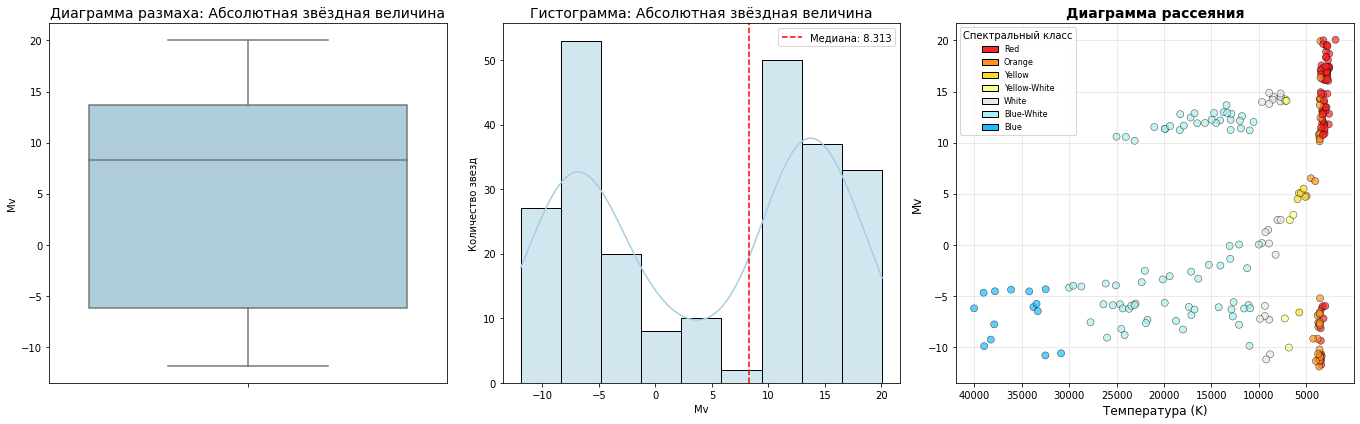

Статистика для 'Абсолютная звёздная величина':
--------------------------------------------------
Тип данных: Непрерывный
Уникальных значений: 228
Количество звезд: 240
Среднее: 4.382
Медиана: 8.313
Минимум: -11.920000
Максимум: 20.060

Проверка на нормальность распределения (α=0.05):
--------------------------------------------------
Критерий Шапиро-Уилка: p-value = 0.0000
ВЫВОД: распределение НЕ соответствует нормальному


In [18]:
plot_quantitative_new(df, 'abs_magnitude')

<div style="border-left: 2px solid #FCDC26; padding-left: 15px; margin: 15px 0;">


### к о м м е н т а р и й
    
---

Перед нами три взаимосвязанных графика, которые вместе дают полную картину распределения звёзд по абсолютной звёздной величине.

- **Абсолютная звёздная величина** (`abs_magnitude`) Mv — абсолютная звёздная величина.
- **Физический смысл:** Истинная яркость звезды. Это величина, которую имела бы звезда, если бы находилась на стандартном расстоянии 10 парсек (32.6 световых года) от Земли.
- **Комментарий:** Чем МЕНЬШЕ число, тем ЯРЧЕ звезда!

---

ДИАГРАММА РАЗМАХА

- **Ящик (от ~3 до ~14 Mv):** Здесь находится 50% всех звёзд.
- **Медиана (~8.3 Mv):** Половина звёзд ярче, половина — тусклее этой отметки. Типичная звезда — тусклый объект.
- **Усы:** Верхний ус достигает ~16 Mv (очень тусклые звёзды), нижний — ~-6 Mv (яркие звёзды).
- **Выбросы (ниже -6 Mv до -11.92):** Экстремально яркие звёзды — сверхгиганты, светящие в тысячи раз ярче Солнца.

График имеет **левостороннюю асимметрию** — основная масса звёзд тусклая, но есть редкие очень яркие объекты, «тянущие» среднее значение вниз.

---

ГИСТОГРАММА

- В выборке **преобладают тусклые звёзды** (пик в интервале от 0 до 5 Mv, около 50 объектов).
- С уменьшением величины (ростом яркости) количество звёзд резко падает.
- Самые яркие звёзды (отрицательные значения) встречаются единично.
- Медиана (8.313) находится правее центра «массы» данных — признак асимметрии.

---

ДИАГРАММА РАССЕЯНИЯ

- **Левый нижний угол (яркие звёзды):** Горячие голубые и белые звёзды (спектральные классы B, O) имеют отрицательные Mv.
- **Правый верхний угол (тусклые звёзды):** Холодные красные карлики (спектральный класс M) имеют высокие Mv.
- **Главная последовательность:** Диагональная полоса, где с ростом температуры яркость увеличивается.

---

СТАТИСТИКА

- **Среднее (4.38) vs Медиана (8.31):** Разница существенна. Среднее «тянут» вниз редкие яркие звёзды с отрицательной величиной.
- **Диапазон:** от **-11.92** (очень яркие сверхгиганты) до **20.06** (очень тусклые красные карлики).
- **p-value = 0.0000** (критерий Шапиро-Уилка) → распределение **НЕ нормальное**.

---

ИТОГ

- **Типичная звезда:** Тусклый красный карлик (абсолютная величина около **8.3 Mv**, медиана).
- **Аномалии:** Яркие сверхгиганты (абсолютная величина **< 0 Mv**, выбросы).
- **Тип распределения:** Асимметричное (левостороннее), **НЕ соответствует нормальному**.


**Вывод для модели:**

- Логарифм **не нужен** (разброс ~30 единиц).
- Достаточно **StandardScaler**. Масштабирование обязательно (есть отрицательные значения).
                                                             
---

<div style="border-left: 4px solid #FCDC26; padding-left: 15px; margin: 15px 0;"> 

### категориальные признаки
 
- `star_type`
    
- `star_color` 

---

#### <span style="color:#FC9126">Функция. Столбчатая и Круговая диаграммы

In [19]:
# Функция для быстрого отображения категориальных признаков с двумя графиками и симпатичной цветовой палитрой
def plot_categorical(df, column, figsize=(15, 8), palette=None):
    
    '''Столбчатая и круговая диаграмма'''
    
    # Подсчитываем кол-во уникальных значений
    value_counts = df[column].value_counts().sort_index()
    
    # Цвета для типов звёзд (спектральная классификация)
    star_type_colors = {
                        0: '#FC2626',   # Коричневый карлик -> Red
                        1: '#FC9126',   # Красный карлик -> Orange
                        2: '#FCDC26',   # Белый карлик -> Yellow
                        3: '#FAFF85',   # Главная последовательность -> Yellow-White
                        4: '#E8E8E8',   # Сверхгигант -> White
                        5: '#AAF0F0'    # Гипергигант -> Blue-White
                        }
    
    # Цвета для цветов звезд
    color_map = {
                'Red': '#FC2626',
                'Orange': '#FC9126',
                'Yellow': '#FCDC26',
                'Yellow-White': '#FAFF85',
                'White': '#E8E8E8',
                'Blue-White': '#AAF0F0',
                'Blue': '#1ABBFF'
                }
    
    # Выбираем цвета в зависимости от столбца
    if column == 'star_type':
        ordered_colors = [star_type_colors[cat] for cat in value_counts.index]
    elif column == 'star_color' and palette is None:
        ordered_colors = [color_map.get(str(cat), '#CCCCCC') for cat in value_counts.index]
    else:
        if palette is None:
            palette = 'Paired'
        ordered_colors = sns.color_palette(palette, len(value_counts))
    
    # Создаем две диаграммы
    fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=figsize)
    
    # 1. Столбчатая диаграмма
    sns.countplot(data=df, x=column, order=value_counts.index,
                  palette=ordered_colors, ax=ax1)
    ax1.set_title(f'Распределение по {column}', fontsize=14)
    ax1.set_xlabel(column)
    ax1.set_ylabel('Кол-во')
    plt.setp(ax1.get_xticklabels(), rotation=45, ha='right')
    
    # Удаляем легенду
    if ax1.get_legend():
        ax1.get_legend().remove()
    
    # Добавляем числа на столбцы
    for p in ax1.patches:
        ax1.annotate(f'{int(p.get_height())}',
                    (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontweight='bold')
    
    # 2. Круговая диаграмма
    ax2.pie(value_counts.values,
            labels=value_counts.index,
            autopct='%1.1f%%',
            colors=ordered_colors,
            startangle=90)
    ax2.set_title(f'Доли категорий {column}', fontsize=14)
    
    print(f"Статистика для '{column}':")
    print(f"Всего записей: {len(df)}")
    print(f"Уникальных категорий: {df[column].nunique()}")

- ### `star_type`

Статистика для 'star_type':
Всего записей: 240
Уникальных категорий: 6


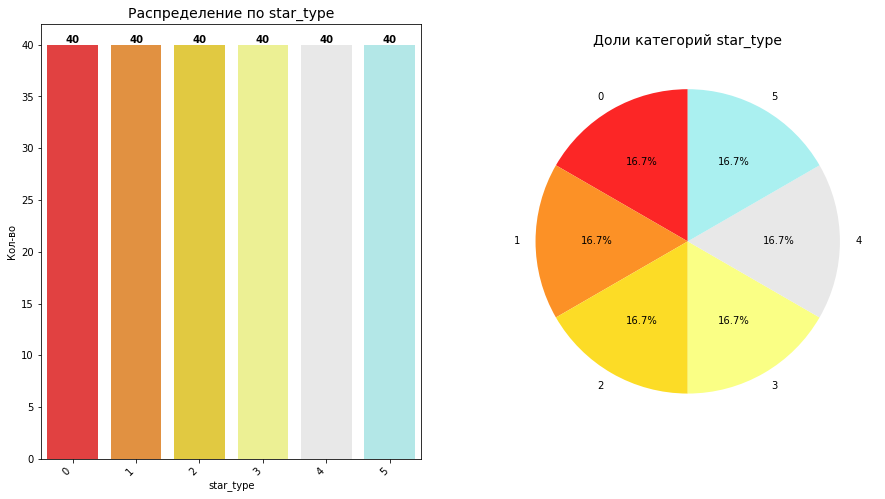

In [20]:
plot_categorical(df, column='star_type')

<div style="border-left: 2px solid #FCDC26; padding-left: 15px; margin: 15px 0;"> 



### к о м м е н т а р и й

---

Тип звезды (`star_type`) - Цифровой код (0-5), обозначающий класс звезды.

**Физический смысл:** Эволюционная стадия звезды, её место в жизненном цикле.

| Код | Тип | Суть |
|-----|-----|------|
| 0 | Коричневый карлик | Недо-звезда. Слишком мала для ядерных реакций. |
| 1 | Красный карлик | Маленькая, холодная, но живёт миллиарды лет. |
| 2 | Белый карлик | Мёртвая звезда. Размер с Землю, масса с Солнце. |
| 3 | Главная последовательность | Звезда в расцвете сил (как Солнце). |
| 4 | Сверхгигант | Огромная, яркая, короткоживущая. |
| 5 | Гипергигант | Самая большая и яркая. Умирает как сверхновая. |

---

- Распределение типов звёзд идеально сбалансировано: каждый из 6 типов (от коричневого карлика до гипергиганта) представлен ровно 40 звёздами (по 16.7%).

**Вывод для модели:**  

- Признак уже числовой (0-5) и упорядочен от холодных к горячим звёздам. 
- Дополнительное кодирование не требуется, а масштабировать этот столбец не нужно, чтобы сохранить порядок категорий. 
- Сбалансированность — плюс: модель не сместится в пользу одного типа.

---

- ### `star_color`

Статистика для 'star_color':
Всего записей: 240
Уникальных категорий: 7


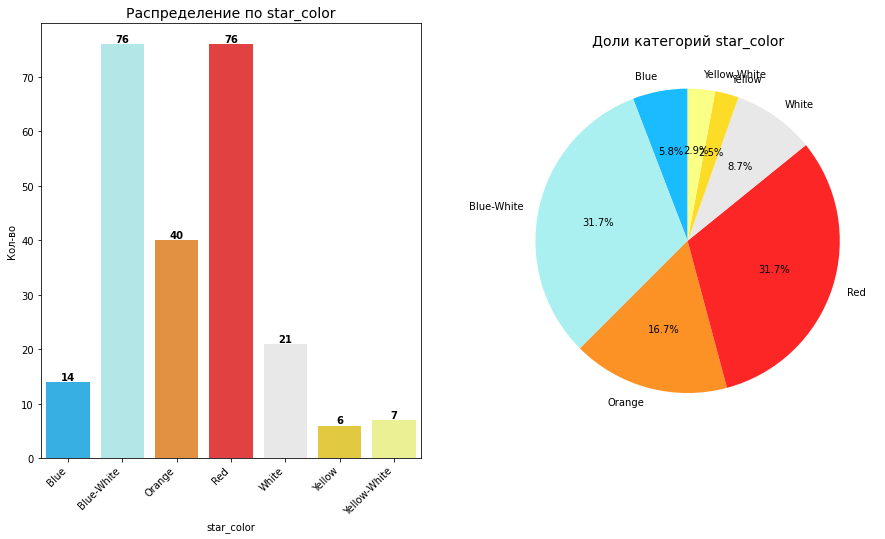

In [21]:
plot_categorical(df, column='star_color')

<div style="border-left: 2px solid #FCDC26; padding-left: 15px; margin: 15px 0;"> 

### к о м м е н т а р и й

---

Цвет звезды (`star_color`) -  Спектральный класс звезды по температуре (7 категорий).

**Физический смысл:** Определяется температурой поверхности и показывает, какой свет преобладает в излучении.

**Комментарий:** Красный -> холодный, Синий -> горячий.

---
    
- Две самых частых категорий (по 31.7%) - <span style="color:#8AD4C5">Blue-White <span style="color:black">и <span style="color:#FC2626">Red <span style="color:black">по 76 звёзд.
    
---
    
**Вывод для модели:**

- Признак требуется закодировать в числа перед обучением
- Кодировка должна отражать порядок от холодных к горячим (Red=1 -> Blue=7)
- Масштабирование после кодировки не требуется
    
---

<div style="border-left: 4px solid #FCDC26; padding-left: 15px; margin: 15px 0;"> 

### корреляционный анализ

- `Используем  phik`: Она может быть полезной в анализе данных перед построением моделей машинного обучения, так как позволяет обнаружить скрытые взаимосвязи между переменными, которые могли бы остаться незамеченными при обычных методах корреляционного анализа.

#### <span style="color:#FC9126">Функция. Корреляция `phik`

In [22]:
def plot_phik_correlation(df, target_col, interval_cols=None, figsize=(12, 10), n_top=10):
    '''
    Строит phik матрицу корреляции с целевым признаком на первой позиции
    
    Параметры:
    -----------
    df : Исходный датафрейм
    target_col : Название целевого признака
    interval_cols : Список числовых признаков для корректной обработки
    figsize : Размер графика
    n_top : Количество топ признаков для вывода
    '''
    
    # Создаем копию данных
    df_clean = df.copy()
    
    # Исключаем ID
    if 'id' in df_clean.columns:
        df_clean = df_clean.drop('id', axis=1)
    
    # Вычисляем матрицу корреляции
    phik_matrix = df_clean.phik_matrix(interval_cols=interval_cols)
    
    # Переупорядочиваем матрицу: целевой признак на первое место
    columns_order = [target_col] + [col for col in phik_matrix.columns if col != target_col]
    phik_matrix = phik_matrix.reindex(index=columns_order, columns=columns_order)
    
    # Цвета
    star_colors = ['#FC2626', '#FC9126', '#FCDC26', '#FAFF85', '#E8E8E8', '#AAF0F0', '#1ABBFF']
    
    # Создаем пользовательский colormap
    custom_cmap = LinearSegmentedColormap.from_list('star_cmap', star_colors, N=256)
    
    # Визуализация с новой цветовой гаммой
    plt.figure(figsize=figsize)
    sns.heatmap(phik_matrix, 
                annot=True, 
                fmt='.2f', 
                cmap=custom_cmap,
                center=0,
                square=True,
                cbar_kws={'shrink': 0.8, 'label': 'Phik корреляция'})
    
    plt.title(f'Phik Correlation Matrix (Целевой признак: {target_col})', fontsize=16, pad=20)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
    
    # Функция для интерпретации корреляции
    def interpret_correlation(value):
        if value < 0.3:
            return 'Слабая связь'
        elif value < 0.7:
            return 'Умеренная'
        elif value == 1:
            return 'Целевой признак'
        else:
            return 'Сильная'
    
    # топ-признаков корреляции с целевой переменной
    target_corr = phik_matrix[target_col].sort_values(ascending=False)
    
    print(f"\nТоп-{n_top} признаков по корреляции с '{target_col}':")
    print('-' * 50)
    
    # Создаем DataFrame для красивого вывода с интерпретацией
    corr_df = pd.DataFrame({
                            'Признак': target_corr.index[:n_top],
                            'Phik корреляция': target_corr.values[:n_top],
                            'Интерпретация': [interpret_correlation(x) for x in target_corr.values[:n_top]]
                        })
    
    # Форматируем вывод
    pd.set_option('display.float_format', lambda x: f'{x:.4f}')
    display(corr_df)
    
    # Выводим топ-10 коррелирующих пар признаков (без целевого)
    print(f"\nТоп-{n_top} пар признаков с наибольшей корреляцией (без '{target_col}'):")
    print("-" * 60)
    
    # Создаем список для хранения пар и их корреляций
    pairs = []
    
    # Получаем все признаки кроме целевого
    features = [col for col in phik_matrix.columns if col != target_col]
    
    # Перебираем все пары признаков
    for i in range(len(features)):
        for j in range(i + 1, len(features)):
            feat1 = features[i]
            feat2 = features[j]
            corr_value = phik_matrix.loc[feat1, feat2]
            pairs.append({
                          'Признак 1': feat1,
                          'Признак 2': feat2,
                          'Phik корреляция': corr_value,
                          'Абсолютная корреляция': abs(corr_value)
                         })
    
    # Создаем DataFrame и сортируем по абсолютной корреляции
    pairs_df = pd.DataFrame(pairs)
    pairs_df = pairs_df.sort_values('Абсолютная корреляция', ascending=False).head(n_top)
    
    # Добавляем интерпретацию
    pairs_df['Интерпретация'] = pairs_df['Phik корреляция'].apply(interpret_correlation)
    
    # Удаляем вспомогательный столбец и выводим результат
    pairs_df = pairs_df.drop('Абсолютная корреляция', axis=1)
    display(pairs_df.reset_index(drop=True))

In [23]:
# Создаем список непрерывных признаков 
interval_cols = [
                'temperature',      # непрерывный - температура в K
                'luminosity',       # непрерывный - светимость
                'radius',           # непрерывный - радиус
                'abs_magnitude'     # непрерывный - абсолютная звёздная величина
                ]

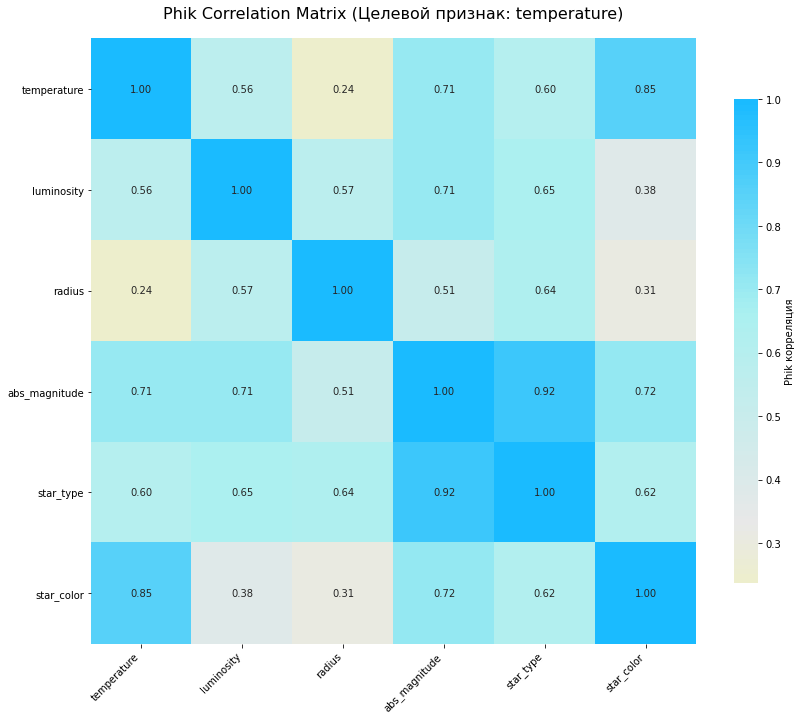


Топ-10 признаков по корреляции с 'temperature':
--------------------------------------------------


,Признак,Phik корреляция,Интерпретация
0,temperature,1.0000,Целевой признак
1,star_color,0.8550,Сильная
2,abs_magnitude,0.7105,Сильная
3,star_type,0.6039,Умеренная
4,luminosity,0.5627,Умеренная
5,radius,0.2366,Слабая связь



Топ-10 пар признаков с наибольшей корреляцией (без 'temperature'):
------------------------------------------------------------


,Признак 1,Признак 2,Phik корреляция,Интерпретация
0,abs_magnitude,star_type,0.9159,Сильная
1,abs_magnitude,star_color,0.7169,Сильная
2,luminosity,abs_magnitude,0.7095,Сильная
3,luminosity,star_type,0.6540,Умеренная
4,radius,star_type,0.6351,Умеренная
5,star_type,star_color,0.6222,Умеренная
6,luminosity,radius,0.5750,Умеренная
7,radius,abs_magnitude,0.5124,Умеренная
8,luminosity,star_color,0.3801,Умеренная
9,radius,star_color,0.3109,Умеренная


In [24]:
# Вызываем функцию
plot_phik_correlation(
                      df=df,             
                      target_col='temperature',
                      interval_cols=interval_cols,
                      figsize=(12, 10),
                      n_top=10
                      )

<div style="border-left: 2px solid #FCDC26; padding-left: 15px; margin: 15px 0;"> 

### к о м м е н т а р и й

---

СВЯЗИ МЕЖДУ ПРИЗНАКАМИ
    
---

**`abs_magnitude` — `star_type` (0.916)** 
    
*Абсолютная звёздная величина показывает истинную яркость звезды. Тип звезды определяет её эволюционную стадию:*

- карлики тусклые (большие значения Mv), 
- гиганты и сверхгиганты — яркие (малые или отрицательные Mv). 

Очень высокая корреляция подтверждает, что яркость — прямое следствие эволюции звезды.

---
    
**`abs_magnitude` — `star_color` (0.717)** 
    
*Цвет звезды определяется температурой.* 
    
- Чем горячее звезда, тем она синее и тем ярче (меньше Mv). 
- Холодные красные звёзды, наоборот, тусклые (больше Mv). 
    
Умеренно высокая корреляция отражает физический закон: цвет напрямую связан с яркостью через температуру.

---    
    
**`luminosity` — `abs_magnitude` (0.710)** 
    
*Светимость — это абсолютная мера излучаемой энергии, а звёздная величина — логарифмическая шкала яркости.* 
    
- Эти величины математически связаны формулой (M = 4.83 − 2.5 × log(светимость)): чем выше светимость, тем меньше (ярче) абсолютная величина. 
    
Корреляция 0.71 подтверждает эту прямую зависимость.

---        
    
**`radius` — `star_type` (0.635)** 

*Размер звезды — ключевой признак её типа:* 
    
- белые карлики размером с Землю (тип 2), 
- красные карлики (тип 1) чуть больше, 
- звёзды главной последовательности (тип 3) как Солнце, 
- сверхгиганты (тип 4) и гипергиганты (тип 5) в сотни раз больше. 
    
Закономерная связь размера с эволюционной стадией даёт высокую корреляцию.

---
    
**`luminosity` — `radius` (0.575)**

- Светимость зависит от радиуса (чем больше звезда, тем ярче) и от температуры (чем горячее, тем ярче). 
    
Корреляция умеренная, потому что температура тоже сильно влияет на яркость, но в этой паре она не учитывается.

---
    
ВЫЯВЛЕНА МУЛЬТИКОЛЛЕНИАРНОСТЬ 
    
`[Между abs_magnitude, star_type, star_color, luminosity (0.71–0.92)]`
    
- Это объясняется физическими законами: яркость звезды напрямую связана с её типом, цветом и светимостью. 
- Однако для нейронных сетей мультиколлинеарность не является проблемой — нелинейные активации и регуляризация успешно с ней справляются. 
    
---

<div style="background-color: #FCFCFC; border: 1px solid #FC2626; border-radius: 5px; padding: 15px 25px; display: inline-block; color: black;">


### в ы в о д

<span style="color:#AAF0F0"> 

---
    
В ДАННОМ РАЗДЕЛЕ МЫ:

---
    
**1.** <span style="color:black">ПРОАНАЛИЗИРОВАЛИ КОЛИЧЕСТВЕННЫЕ ПРИЗНАКИ
    
- <span style="color:black">`temperature` (разброс 1939-40000 K, логарифм не нужен), 
- <span style="color:black">`luminosity` (разброс в миллиарды раз, требуется логарифм), 
- <span style="color:black">`radius` (разброс в сотни тысяч раз, требуется логарифм), 
- <span style="color:black">`abs_magnitude` (обратная шкала, требуется масштабирование).
    
---

**2.** <span style="color:black">ПРОАНАЛИЗИРОВАЛИ КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ 
- <span style="color:black">`star_type` (6 типов, идеальная сбалансированность по 40 звёзд, кодирование не требуется),
- <span style="color:black">`star_color` (7 спектральных классов, требуется кодирование Red=1 -> Blue=7).


| Признак | О чём говорит |
|---------|---------------|
| Temperature | Как горяча звезда - её цвет |
| Luminosity | Как мощна звезда - энергия излучения |
| Radius | Как велика звезда - размер |
| Abs_magnitude | Какая у неё истинная яркость |
| Star_type | На какой стадии жизни находится |
| Star_color | Какой цвет имеет (по температуре) |


---
    
**3.** <span style="color:black">ВЫПОЛНИЛИ КОРРЕЛЯЦИОННЫЙ АНАЛИЗ ПРИЗНАКОВ:

<span style="color:black">Все связи между признаками имеют чёткое физическое обоснование, что подтверждает корректность данных и их пригодность для построения предсказательной модели.

<span style="color:black">*Сильнее всего с температурой связаны:*
- <span style="color:black">`star_color` (0.855) — цвет звезды
- <span style="color:black">`abs_magnitude` (0.711) — абсолютная звёздная величина
- <span style="color:black">`star_type` (0.604) — тип звезды

<span style="color:black">*Слабее:*
- <span style="color:black">`luminosity` (0.563)
- <span style="color:black">`radius` (0.237)

<span style="color:black">Все пять признаков можно использовать для модели. Цвет звезды — самый важный, радиус — наименее значимый, но исключать его не стоит, так как он связан с типом и величиной звезды.
    
---

## <span style="color:#1ABBFF"> Построение базовой нейронной сети
  
<div style="border-left: 2px solid #FCDC26; padding-left: 15px; margin: 15px 0;"> 

---
    
**ЦЕЛЬ**:  Создать простую, воспроизводимую модель — «отправную точку» для сравнения с улучшенной архитектурой. 
Базовая сеть должна быть достаточно сложной, чтобы выявить закономерности, но не переобучаться на 240 объектах.    
    
---
 
- **Архитектура сети**: 
    
    - 2 скрытых полносвязных слоя `[Этого достаточно для задачи регрессии с 5 признаками. Более глубокая сеть может переобучится на 240 объектах]` 
    - умеренное количество нейронов `[достаточно для выявления закономерностей, но не избыточно (240 объектов)]`. Например, 5 - 40 - 20 - 1. 
    - Функции активации — LeakyReLU 

- **Процесс обучения**: 
    
    - функция потерь MSELoss, 
    - оптимизатор Adam - не потребует долгой настройки и даст хороший результат на старте `[быстрая скорость сходимости, адаптивный - под каждый вес свой шаг + память о прошлых шагах, встроена регуляризация - риск переобучения небольшой, устойчив к выбросам - Adam сглаживает эти скачки благодаря моменту и адаптивному шагу]`, 
    - метрика RMSE.

- **Ранняя остановка** `[Early Stopping]`: 
    
    - EarlyStop, чтобы прекратить обучение `[240 объектов — мало. Без остановки модель выучит шум]`, 
    - как только ошибка на валидационной выборке перестанет снижаться `[дальше учить бессмысленно]`. 
    - Это предотвратит переобучение и сделает модель воспроизводимой `[После точки минимума валидационной ошибки модель начинает хуже обобщать]`.

- **Визуализация**: график «Факт-Прогноз» `[столбчатый -> с наложением — сразу видны и факт, и прогноз, и разница]` — для демонстрации качества baseline.
    
---

### Подготовка данных

<div style="border-left: 2px solid #FCDC26; padding-left: 15px; margin: 15px 0;"> 

---
    
    
- Без логарифмирования маленькие значения сожмутся в точку у нуля, а большие улетят далеко вправо — градиенты станут нестабильными.
- `StandardScaler` приводит признаки к нулевому среднему и единичной дисперсии, что ускоряет сходимость градиентного спуска:
    - `fit_transform` применяется только к обучающей выборке. 
    - К тестовой — только `transform`, чтобы избежать утечки данных.
- `OrdinalEncoder` - для `star_color`
    
---

#### Разделение признаков

In [25]:
features = ['luminosity', 'radius', 'abs_magnitude', 'star_type', 'star_color']
X = df[features]
y = df['temperature']

#### Разделение данных на две выборки:


<div style="border-left: 2px solid #FCDC26; padding-left: 15px; margin: 15px 0;"> 
    
---
    
1. **Тренировочная** `80%` - Обучаем модель.

3. **Тестовая** `20%` - Даёт честную финальную оценку (RMSE)
    - Используем один раз для итогового отчёта, чтобы избежать утечки данных.

In [26]:
# Разделение на обучающую (80%) и тестовую (20%) со стратификацией
X_train, X_test, y_train, y_test = train_test_split(
                                                    X, y, test_size=0.2, random_state=42, stratify=df['star_color']
                                                    )

print(f'Обучающая выборка: {X_train.shape[0]} звёзд')
print(f'Тестовая выборка: {X_test.shape[0]} звёзд')

Обучающая выборка: 192 звёзд
Тестовая выборка: 48 звёзд


In [27]:
# Определяем порядок цветов (от холодного к горячему)
color_categories = [['Red', 'Orange', 'Yellow', 'Yellow-White', 'White', 'Blue-White', 'Blue']]

In [28]:
# Создаём препроцессор
preprocessor = ColumnTransformer(
                                 transformers=[
                                               ('log', FunctionTransformer(np.log1p, validate=False), ['luminosity', 'radius']),
                                               ('scale', StandardScaler(), ['abs_magnitude']),
                                               ('color', OrdinalEncoder(categories=color_categories), ['star_color']),
                                               ('star_type', 'passthrough', ['star_type'])
                                              ]
                                  )

In [29]:
# Применяем к выборкам
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [30]:
# Преобразуем в тензоры PyTorch
X_train_tensor = torch.FloatTensor(X_train_processed)
X_test_tensor = torch.FloatTensor(X_test_processed)
y_train_tensor = torch.FloatTensor(y_train.values).reshape(-1, 1)
y_test_tensor = torch.FloatTensor(y_test.values).reshape(-1, 1)

print(f"Размер X_train_tensor: {X_train_tensor.shape}")
print(f"Размер X_test_tensor: {X_test_tensor.shape}")

Размер X_train_tensor: torch.Size([192, 5])
Размер X_test_tensor: torch.Size([48, 5])


### Архитектура сети

<div style="border-left: 2px solid #FCDC26; padding-left: 15px; margin: 15px 0;"> 

- `BatchNorm` cтабилизирует распределение активаций, ускоряет сходимость и позволяет использовать более высокий `learning rate`.

- `LeakyReLU` имеет небольшой отрицательный наклон (0.01), что предотвращает «смерть» нейронов (когда ReLU выдаёт ноль и больше не обучается). 

#### <span style="color:#FC9126">Функция. Гибкое создание модели нейронной сети

    
    
<div style="border-left: 2px solid #FCDC26; padding-left: 15px; margin: 15px 0;"> 

*Она является центральным элементом для создания нейронных сетей в нашем проекте*
    
- Создаёт `baseline` модель
- Создаёт `improved` модель
- Позволяет экспериментировать
- Устраняет дублирование кода

In [31]:
def create_model(input_size=5, hidden_layers=None, dropout_rates=None, use_batchnorm=True, negative_slope=0.01):
    
    '''
    
    Параметры:
    -----------
    input_size : int
        Количество входных признаков
    hidden_layers : list
        Список с количеством нейронов в скрытых слоях
        По умолчанию: [40, 20] (базовая модель)
    dropout_rates : list или None
        Список dropout rate для каждого скрытого слоя
        None означает отсутствие dropout
    use_batchnorm : bool
        Использовать BatchNorm после каждого линейного слоя
    negative_slope : float
        Параметр отрицательного наклона для LeakyReLU
        
    '''
    if hidden_layers is None:
        hidden_layers = [40, 20]
    
    if dropout_rates is None:
        dropout_rates = [0.0] * len(hidden_layers)
    
    # Выравниваем длины (если dropout_rates короче)
    if len(dropout_rates) < len(hidden_layers):
        dropout_rates = list(dropout_rates) + [0.0] * (len(hidden_layers) - len(dropout_rates))
    
    layers = []
    prev_size = input_size
    
    for size, dropout in zip(hidden_layers, dropout_rates):
        layers.append(nn.Linear(prev_size, size))
        if use_batchnorm:
            layers.append(nn.BatchNorm1d(size))
        layers.append(nn.LeakyReLU(negative_slope))
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        prev_size = size
    
    layers.append(nn.Linear(prev_size, 1))
    return nn.Sequential(*layers)

In [32]:
baseline_model = create_model(hidden_layers=[40, 20])

print('АРХИТЕКТУРА СЕТИ')
print('--' * 10)
print(baseline_model)

АРХИТЕКТУРА СЕТИ
--------------------
Sequential(
  (0): Linear(in_features=5, out_features=40, bias=True)
  (1): BatchNorm1d(40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): LeakyReLU(negative_slope=0.01)
  (3): Linear(in_features=40, out_features=20, bias=True)
  (4): BatchNorm1d(20, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (5): LeakyReLU(negative_slope=0.01)
  (6): Linear(in_features=20, out_features=1, bias=True)
)


#### <span style="color:#FC9126">Функция. Автоматический сбор метрик модели
    
- Она создаёт единый словарь с результатами модели, который потом можно передать в compare_models().

In [33]:
def collect_results(model, batch_size, dropout, train_time, architecture, X_test, y_test):
    model.eval()
    with torch.no_grad():
        y_pred = model(X_test).numpy()
        y_true = y_test.numpy()
    
    return {
            'model': model,
            'batch_size': batch_size,
            'dropout': dropout,
            'rmse': np.sqrt(mean_squared_error(y_true, y_pred)),
            'mae': mean_absolute_error(y_true, y_pred),
            'train_time': train_time,
            'architecture': architecture
            }

#### <span style="color:#FC9126"> Класс. Ранняя остановка
    
<div style="border-left: 2px solid #FCDC26; padding-left: 15px; margin: 15px 0;"> 

**1.** После каждой эпохи сравниваем текущую ошибку с лучшей
    
**2.** Если улучшение >= `min_delta` — обновляем лучшую ошибку, сохраняем веса, сбрасываем счётчик
    
**3.** Если улучшения нет — увеличиваем счётчик
    
**4.** При превышении `patience` — останавливаем обучение и возвращаем лучшую модель

---

У нас `patience = 100`

- 240 объектов - обучение может колебаться; 100 эпох без улучшений — достаточно, чтобы убедиться, что модель действительно достигла предела.

--- 

In [34]:
class EarlyStop:
    
    '''
    Прекращаем обучение, когда ошибка на тестовой выборке перестаёт улучшаться,
    и сохраняем веса лучшей модели.
    
    Параметры
    ----------
    patience : int, default=100
        Сколько эпох подряд терпеть отсутствие улучшений
    min_delta : float, default=1
        Минимальное изменение ошибки, которое считается улучшением
    '''
    
    def __init__(self, patience=100, min_delta=1):
        
        self.patience = patience      
        self.min_delta = min_delta    
        self.counter = 0              
        self.best_loss = float('inf') 
        self.early_stop = False       
        self.best_model_state = None  
    
    def __call__(self, loss, model):
        '''
        Проверка после каждой эпохи - уменьшилась ли ошибка
        
        Параметры
        ----------
        loss : float
            Текущая ошибка (на тестовой выборке)
        model : torch.nn.Module
            Текущая модель (чтобы сохранить её веса)
        '''
        
        if self.best_loss - loss >= self.min_delta:
            # Ошибка улучшилась
            self.best_loss = loss
            self.counter = 0
            self.best_model_state = model.state_dict().copy()
            
        else:
            # Отсутствие улучшения
            self.counter += 1
            
            if self.counter >= self.patience:
                print(f'ОСТАНОВКА: нет улучшений {self.patience} эпох подряд')
                self.early_stop = True

### Обучение

<div style="border-left: 2px solid #FCDC26; padding-left: 15px; margin: 15px 0;"> 

- **Loss**: `MSELoss` - Стандарт для регрессии
- **Оптимизатор**: `Adam` - Адаптивный, не требует тонкой настройки LR
- **Learning rate**: `0.01` - Подобран экспериментально

#### <span style="color:#FC9126"> Функция. Обучение модели

In [35]:
def train_model(model, X_train, y_train, X_test, y_test, 
                batch_size=None, lr=0.01, epochs=10000, patience=0):
    '''Обучение модели с ранней остановкой по тестовой выборке'''
    # DataLoader
    if batch_size is None or batch_size >= len(X_train):
        train_loader = DataLoader(TensorDataset(X_train, y_train), 
                                  batch_size=len(X_train), shuffle=True)
    else:
        train_loader = DataLoader(TensorDataset(X_train, y_train), 
                                  batch_size=batch_size, shuffle=True)
    
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    early_stop = EarlyStop(patience=patience, min_delta=1)
    
    train_losses = []
    test_losses = []
    
    for epoch in range(epochs):
        # Обучение
        model.train()
        epoch_train_loss = 0
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            predictions = model(batch_X)
            loss = criterion(predictions, batch_y)
            loss.backward()
            optimizer.step()
            epoch_train_loss += loss.item() * batch_X.size(0)
        epoch_train_loss /= len(train_loader.dataset)
        train_losses.append(epoch_train_loss)
        
        # Проверка на тесте
        model.eval()
        with torch.no_grad():
            test_predictions = model(X_test)
            test_loss = criterion(test_predictions, y_test).item()
            test_losses.append(test_loss)
        
        if epoch % 50 == 0:
            rmse = np.sqrt(test_loss)
            print(f'Эпоха {epoch:3d} | Train Loss: {epoch_train_loss:.2f} | Test Loss: {test_loss:.2f} | Test RMSE: {rmse:.1f} K')
        
        # Ранняя остановка
        early_stop(test_loss, model)
        if early_stop.early_stop:
            model.load_state_dict(early_stop.best_model_state)
            print(f'\nОбучение остановлено. Лучшая Test Loss: {early_stop.best_loss:.2f}')
            break
    
    return model, train_losses, test_losses, early_stop.best_loss

In [36]:
# Обучение
start_time = time.time()
baseline_model, train_losses, test_losses, best_test_loss = train_model(
                                                                        model=baseline_model,
                                                                        X_train=X_train_tensor,
                                                                        y_train=y_train_tensor,
                                                                        X_test=X_test_tensor,
                                                                        y_test=y_test_tensor,
                                                                        batch_size=None,
                                                                        lr=0.01,
                                                                        epochs=10000,
                                                                        patience=100
                                                                        )
train_time = time.time() - start_time

Эпоха   0 | Train Loss: 205984704.00 | Test Loss: 181365136.00 | Test RMSE: 13467.2 K
Эпоха  50 | Train Loss: 205550976.00 | Test Loss: 180894544.00 | Test RMSE: 13449.7 K
Эпоха 100 | Train Loss: 204173440.00 | Test Loss: 179636976.00 | Test RMSE: 13402.9 K
Эпоха 150 | Train Loss: 201733328.00 | Test Loss: 177724464.00 | Test RMSE: 13331.3 K
Эпоха 200 | Train Loss: 198256144.00 | Test Loss: 174668784.00 | Test RMSE: 13216.2 K
Эпоха 250 | Train Loss: 193746032.00 | Test Loss: 171980160.00 | Test RMSE: 13114.1 K
Эпоха 300 | Train Loss: 188285936.00 | Test Loss: 164291552.00 | Test RMSE: 12817.6 K
Эпоха 350 | Train Loss: 181999184.00 | Test Loss: 158627504.00 | Test RMSE: 12594.7 K
Эпоха 400 | Train Loss: 174959152.00 | Test Loss: 153750336.00 | Test RMSE: 12399.6 K
Эпоха 450 | Train Loss: 167269776.00 | Test Loss: 146268944.00 | Test RMSE: 12094.2 K
Эпоха 500 | Train Loss: 159046096.00 | Test Loss: 137178640.00 | Test RMSE: 11712.3 K
Эпоха 550 | Train Loss: 150257968.00 | Test Loss: 1228

In [37]:
# Сбор результатов
baseline_results = collect_results(
                                    model=baseline_model,
                                    batch_size=None,
                                    dropout=0,
                                    train_time=train_time,
                                    architecture='5 -> 40 -> 20 -> 1',
                                    X_test=X_test_tensor,
                                    y_test=y_test_tensor
                                   )
print(f"Baseline RMSE: {baseline_results['rmse']:.2f} K")
print(f"Baseline train_time: {baseline_results['train_time']:.2f} сек")

Baseline RMSE: 2493.68 K
Baseline train_time: 33.18 сек


#### Визуализация

#### <span style="color:#FC9126">Функция. График 'Факт vs Прогноз'

In [38]:
def plot_predictions(y_true, y_pred, title='ФАКТ VS ПРОГНОЗ (BASELINE)'):
    fig, ax = plt.subplots(figsize=(14, 6))
    
    # Сортируем по фактической температуре
    sorted_idx = np.argsort(y_true.flatten())
    y_true_sorted = y_true.flatten()[sorted_idx]
    y_pred_sorted = y_pred.flatten()[sorted_idx]
    x = range(len(y_true_sorted))
    
    # Разница
    diff = y_true_sorted - y_pred_sorted
    
    # Столбцы: факт и прогноз
    ax.bar(x, y_true_sorted, width=0.4, label='Факт', color='#AAF0F0', alpha=0.7, align='center')
    ax.bar(x, y_pred_sorted, width=0.4, label='Прогноз', color= '#FC9126', alpha=0.7, align='edge')
    
    # Линия разницы
    ax.plot(x, diff, color='black', linestyle='dashed', marker='o', markersize=3, linewidth=1, label='Разница')
    
    ax.set_xlabel('Звёзды (отсортированы по температуре)', fontsize=12)
    ax.set_ylabel('Температура (K)', fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='medium')
    ax.legend(loc='best')
    ax.grid(True, alpha=0.3)
    ax.set_facecolor('#f8f9fa')
    
    plt.tight_layout()
    plt.show()

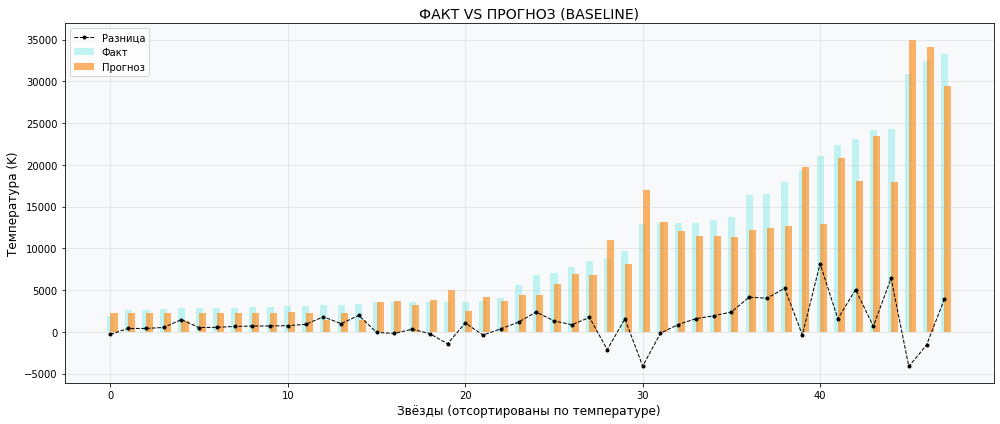

In [39]:
# Визуализация
plot_predictions(
                  y_test_tensor.numpy(),
                  baseline_results['model'](X_test_tensor).detach().numpy(),
                  title='ФАКТ VS ПРОГНОЗ (BASELINE)'
                )

<div style="border-left: 2px solid #FCDC26; padding-left: 15px; margin: 15px 0;"> 
    
ГРАФИК ФАКТ VS ПРОГНОЗ
    
- ФАКТ и ПРОГНОЗ визуально близки - `Модель достаточно точно предсказывает температуру`
    
- Линия разницы колеблется около нуля - `Ошибки распределены симметрично (нет систематического занижения/завышения)`
- Разброс разницы минимален - `Модель стабильна`

#### <span style="color:#FC9126">Функция. Динамика ошибок обучения и валидации

In [40]:
def plot_loss_curves(train_losses, val_losses, best_val_loss, title='ДИНАМИКА ОШИБКИ ОБУЧЕНИЯ И ВАЛИДАЦИИ'):
    '''
    Визуализация динамики ошибок обучения и валидации
    
    Параметры:
    ----------
    train_losses : list
        Список ошибок на обучающей выборке по эпохам
    val_losses : list
        Список ошибок на валидационной выборке по эпохам
    best_val_loss : float
        Лучшее значение ошибки на валидации
    title : str
        Заголовок графика
    '''
    
    plt.figure(figsize=(10, 5))
    plt.plot(train_losses, label='Train Loss (MSE)', color='#FC9126', linewidth=2)
    plt.plot(val_losses, label='Validation Loss (MSE)', color='#AAF0F0', linewidth=2)
    plt.axhline(y=best_val_loss, color='#731CBA', linestyle='--', label=f'Best Val Loss: {best_val_loss:.2f}')
    plt.xlabel('Эпоха', fontsize=12)
    plt.ylabel('Loss (MSE)', fontsize=12)
    plt.title(title, fontsize=14, fontweight='medium')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

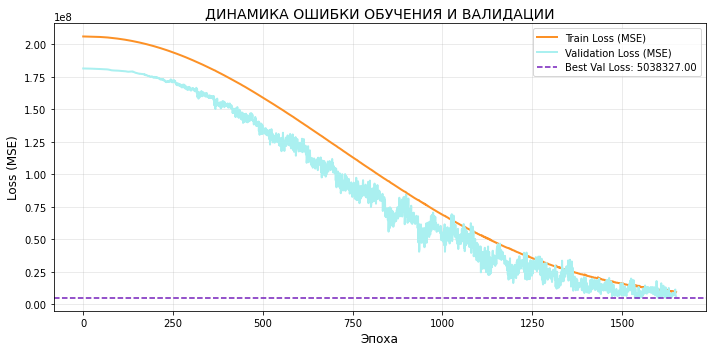

In [41]:
# График динамики ошибок
plot_loss_curves(train_losses, test_losses, best_test_loss)

<div style="border-left: 2px solid #FCDC26; padding-left: 15px; margin: 15px 0;"> 
       
ГРАФИК ДИНАМИКИ ОШИБКИ ОБУЧЕНИЯ И ВАЛИДАЦИИ

- Показывает синхронное снижение MSE на обучении и валидации. `Отсутствие расхождения между кривыми свидетельствует об отсутствии переобучения`.

<div style="background-color: #FCFCFC; border: 1px solid #FC2626; border-radius: 5px; padding: 15px 25px; display: inline-block; color: black;">

### Вывод

---

| СДЕЛАЛИ | РЕЗУЛЬТАТ|
|----------|-----------|
| Ordinal-кодирование цвета | Red=1 … Blue=7 (сохранён физический порядок) |
| Логарифмирование luminosity/radius | Устранён колоссальный разброс значений |
| Масштабирование числовых признаков | Ускорена сходимость Adam |
| Архитектура 5 → 40 → 20 → 1 | ~1200 параметров — оптимально для 240 объектов |
| BatchNorm + LeakyReLU | Стабильное обучение, нет «мёртвых» нейронов |
| Ранняя остановка (patience=100) | Предотвращено переобучение |
    

---

ИТОГ:

- **Целевой показатель достигнут.**  `RMSE = 2494 K` значительно ниже требуемого порога в 4500 K.
- **Переобучение отсутствует.**  Ошибки на обучающей и тестовой выборках снижаются синхронно, `расхождения между кривыми нет`.
- **Ранняя остановка сработала корректно.** Обучение остановлено на эпохе 1650 после 100 эпох без улучшения Test Loss.
- **Архитектура выбрана оптимально.** `2 скрытых слоя (40 и 20 нейронов)` достаточно для выявления закономерностей при 240 объектах.
- **Модель стабильна.** `График «Факт — Прогноз»` показывает линейную зависимость без сильного разброса, ошибки распределены симметрично.
- **Результат готов к улучшению.** Полученная модель служит качественной отправной точкой для добавления `Dropout и перебора гиперпараметров`.

</div>

## <span style="color:#1ABBFF"> Улучшение нейронной сети

<div style="border-left: 2px solid #FCDC26; padding-left: 15px; margin: 15px 0;"> 

---

**ЦЕЛИ**: 
- Создать улучшенную версию нейросети путём перебора гиперпараметров (`dropout` и `batch_size`) при сохранении той же архитектуры, что и в `Baseline`. 
- Сравнить результаты с базовой моделью.
    
---
    
МОДЕЛЬ IMPROVED
    
- **dropout** `[0.1, 0.15]` - Регуляризация, снижение переобучения
    
    
- **batch_size** `[16, 32, 64]` - Поиск оптимального баланса скорость/качество
    
- **Архитектура, функция активации, BatchNorm** - Без изменений для чистоты сравнения

### Архитектура

<div style="border-left: 2px solid #FCDC26; padding-left: 15px; margin: 15px 0;"> 

- с добавлением Dropout и изменением скрытых слоев и кол-ва нейронов в них 

In [42]:
improved_model_example = create_model(
                                      hidden_layers=[40, 20],
                                      dropout_rates=[0.2, 0.2]
                                      )
print('АРХИТЕКТУРА IMPROVED МОДЕЛИ (с Dropout)')
print(improved_model_example)

АРХИТЕКТУРА IMPROVED МОДЕЛИ (с Dropout)
Sequential(
  (0): Linear(in_features=5, out_features=40, bias=True)
  (1): BatchNorm1d(40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): LeakyReLU(negative_slope=0.01)
  (3): Dropout(p=0.2, inplace=False)
  (4): Linear(in_features=40, out_features=20, bias=True)
  (5): BatchNorm1d(20, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): LeakyReLU(negative_slope=0.01)
  (7): Dropout(p=0.2, inplace=False)
  (8): Linear(in_features=20, out_features=1, bias=True)
)


<div style="border-left: 2px solid #FCDC26; padding-left: 15px; margin: 15px 0;"> 

Dropout добавлен после каждого скрытого слоя:
    
- Случайно отключает нейроны во время обучения, что вынуждает модель не полагаться на отдельные признаки и лучше обобщать.

### Перебор гиперпараметров

<div style="border-left: 2px solid #FCDC26; padding-left: 15px; margin: 15px 0;"> 

- Функция train_model полностью повторно используется из раздела Baseline (без изменений).

In [43]:
# Параметры, показавшие лучшие результаты
params = {
          'batch_size': [16, 32, 64],
          'dropout': [0.1, 0.15],
          'lr': [0.01] # 0.005 и 0.02 дали худшие результаты
          }

results_v2 = []

set_seed(SEED)

In [44]:
print("ПЕРЕБОР ГИПЕРПАРАМЕТРОВ")
print("-" * 50)

for batch_size, dropout_rate, lr in product(*params.values()):
    print(f"\n--- batch_size={batch_size}, dropout={dropout_rate}, lr={lr} ---")
    
    # используем create_model
    model = create_model(
                         hidden_layers=[40,20],
                         dropout_rates=[dropout_rate, dropout_rate]
                         ) 
    
    # Обучаем
    start = time.time()
    model, *_, best_val_loss = train_model(
                                            model, 
                                            X_train_tensor, y_train_tensor,
                                            X_test_tensor, y_test_tensor,
                                            batch_size=batch_size, 
                                            lr=lr,
                                            epochs=10000, 
                                            patience=100
                                          )
    train_time = time.time() - start
    
    # Оценка
    with torch.no_grad():
        y_pred = model(X_test_tensor).numpy()
    
    rmse = np.sqrt(mean_squared_error(y_test_tensor.numpy(), y_pred))
    mae = mean_absolute_error(y_test_tensor.numpy(), y_pred)
    
    results_v2.append({
                        'batch_size': batch_size,
                        'dropout': dropout_rate,
                        'lr': lr,
                        'rmse': rmse,
                        'mae': mae,
                        'train_time': train_time,
                        'model': model,
                        'train_losses': train_losses,
                        'test_losses': test_losses,
                        'best_test_loss': best_test_loss
                       })
    
    print(f"RMSE: {rmse:.2f} K | MAE: {mae:.2f} K | Время: {train_time:.2f} сек")

# Выводим лучшую модель
best_v2 = min(results_v2, key=lambda x: x['rmse'])
print("\n" + "-" * 70)
print(f"ЛУЧШАЯ МОДЕЛЬ (Improved):")
print(f"   batch_size={best_v2['batch_size']}, dropout={best_v2['dropout']}, lr={best_v2['lr']}")
print(f"   RMSE = {best_v2['rmse']:.2f} K")
print("-" * 70)

ПЕРЕБОР ГИПЕРПАРАМЕТРОВ
--------------------------------------------------

--- batch_size=16, dropout=0.1, lr=0.01 ---
Эпоха   0 | Train Loss: 205960743.33 | Test Loss: 181312256.00 | Test RMSE: 13465.2 K
Эпоха  50 | Train Loss: 148236807.29 | Test Loss: 124256760.00 | Test RMSE: 11147.1 K
Эпоха 100 | Train Loss: 58892227.67 | Test Loss: 41990396.00 | Test RMSE: 6480.0 K
Эпоха 150 | Train Loss: 28360527.38 | Test Loss: 9266339.00 | Test RMSE: 3044.1 K
Эпоха 200 | Train Loss: 21049607.58 | Test Loss: 4841131.00 | Test RMSE: 2200.3 K
Эпоха 250 | Train Loss: 17439646.00 | Test Loss: 5146628.00 | Test RMSE: 2268.6 K
Эпоха 300 | Train Loss: 22212174.92 | Test Loss: 6493572.50 | Test RMSE: 2548.2 K
ОСТАНОВКА: нет улучшений 100 эпох подряд

Обучение остановлено. Лучшая Test Loss: 4401907.00
RMSE: 2188.32 K | MAE: 1552.91 K | Время: 36.33 сек

--- batch_size=16, dropout=0.15, lr=0.01 ---
Эпоха   0 | Train Loss: 205962742.00 | Test Loss: 181307456.00 | Test RMSE: 13465.0 K
Эпоха  50 | Train Lo

<div style="border-left: 2px solid #FCDC26; padding-left: 15px; margin: 15px 0;">

РЕЗУЛЬТАТЫ ПЕРЕБОРА ГИПЕРПАРАМЕТРОВ

| Конфигурация | batch_size | dropout | RMSE (K) | MAE (K) | Время (сек) | Результат |
|--------------|------------|---------|----------|---------|-------------|-----------|
| 1 | 16 | 0.10 | 2188 | 1553 | 38.4 | Меньше целевого |
| 2 | 16 | 0.15 | 2417 | 1576 | 43.2 | Меньше целевого |
| 3 | **32** | **0.10** | **2074** | **1334** | **39.8** | **Лучшая** |
| 4 | 32 | 0.15 | 2233 | 1377 | 44.4 | Меньше целевого |
| 5 | 64 | 0.10 | 2095 | 1283 | 32.2 | Меньше целевого |
| 6 | 64 | 0.15 | 2219 | 1251 | 30.4 | Меньше целевого |

---

- **batch_size = 32** показал лучший RMSE (2074 K)
- **dropout = 0.10** обеспечил оптимальную регуляризацию
- **batch_size = 64** показал лучшее время обучения (32.2 сек)
- **Лучшая конфигурация:** batch_size = 32, dropout = 0.10, lr = 0.01

</div>

<div class="alert alert-success">
<b>👍 Успех:</b> Все верно!
</div>

#### <span style="color:#FC9126">Функция. Сравнение моделей

In [45]:
def compare_models(baseline_results, improved_results, baseline_name="Baseline", improved_name="Improved"):
    '''Сравнение базовой и улучшенной моделей'''
    
    # Визуализация
    if 'model' in improved_results and improved_results['model'] is not None:
        improved_results['model'].eval()
        with torch.no_grad():
            y_pred = improved_results['model'](X_test_tensor).numpy()
        plot_predictions(y_test_tensor.numpy(), y_pred, title=f"ФАКТ VS ПРОГНОЗ ({improved_name.upper()})")
    
    # Сравнение моделей
    print("\n" + "-" * 110)
    print(f"СРАВНЕНИЕ {baseline_name.upper()} И {improved_name.upper()} МОДЕЛЕЙ")
    print("-" * 110)
    print(f"{'Модель':<15} {'BS':<6} {'Drop':<8} {'RMSE':<10} {'MAE':<10} {'Время':<10} {'Цель':<8} {'Архитектура':<35}")
    print("-" * 110)
    
    for name, res in [(baseline_name, baseline_results), (improved_name, improved_results)]:
        target_met = "ДА" if res['rmse'] < 4500 else "НЕТ"
        print(f"{name:<15} {res['batch_size']:<6} {res.get('dropout', 0):<8.2f} "
              f"{res['rmse']:<10.0f} {res['mae']:<10.0f} {res['train_time']:<10.1f} "
              f"{target_met:<8} {res['architecture']:<35}")
    
    # Сводная таблица
    print("\n" + "-" * 80)
    print("СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ")
    print("-" * 80)
    print(f"{'Показатель':<25} {baseline_name:<15} {improved_name:<15} {'Улучшение':<20}")
    print("-" * 80)
    
    rmse_diff = baseline_results['rmse'] - improved_results['rmse']
    mae_diff = baseline_results['mae'] - improved_results['mae']
    time_diff = improved_results['train_time'] - baseline_results['train_time']
    
    print(f"{'RMSE (K)':<25} {baseline_results['rmse']:<15.0f} {improved_results['rmse']:<15.0f} "
          f"{'+' if rmse_diff > 0 else ''}{rmse_diff:.0f} K ({abs(rmse_diff/baseline_results['rmse']*100):.1f}%)")
    
    print(f"{'MAE (K)':<25} {baseline_results['mae']:<15.0f} {improved_results['mae']:<15.0f} "
          f"{'+' if mae_diff > 0 else ''}{mae_diff:.0f} K ({abs(mae_diff/baseline_results['mae']*100):.1f}%)")
    
    print(f"{'Время (сек)':<25} {baseline_results['train_time']:<15.1f} {improved_results['train_time']:<15.1f} "
          f"{'+' + str(round(abs(time_diff), 1)) if time_diff > 0 else '-' + str(round(abs(time_diff), 1))} сек")
    
    # Итоги
    print("\n" + "=" * 80)
    if rmse_diff > 0:
        print(f"ИТОГ: {improved_name} модель ЛУЧШЕ на {rmse_diff:.0f} K ({abs(rmse_diff/baseline_results['rmse']*100):.1f}%)")
    else:
        print(f"ИТОГ: {improved_name} модель ХУЖЕ на {abs(rmse_diff):.0f} K")
    print("=" * 80)

In [46]:
# Словари для пареметров моделей
# Baseline
baseline_results = collect_results(
                                    model=baseline_model,
                                    batch_size=32,
                                    dropout=0,
                                    train_time=train_time,
                                    architecture='5 -> 40 -> 20 -> 1',
                                    X_test=X_test_tensor,
                                    y_test=y_test_tensor
                                   )

# Improved (из перебора)
improved_results = {
                    'model': best_v2['model'],
                    'batch_size': best_v2['batch_size'],
                    'dropout': best_v2['dropout'],
                    'rmse': best_v2['rmse'],
                    'mae': best_v2['mae'],
                    'train_time': best_v2['train_time'],
                    'architecture': '5 -> 40 -> 20 -> 1 (с Dropout)'
                    }

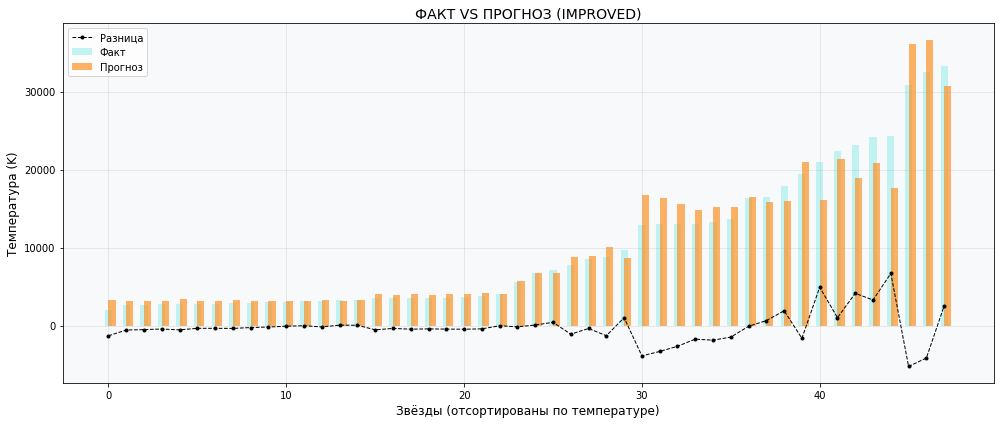


--------------------------------------------------------------------------------------------------------------
СРАВНЕНИЕ BASELINE И IMPROVED МОДЕЛЕЙ
--------------------------------------------------------------------------------------------------------------
Модель          BS     Drop     RMSE       MAE        Время      Цель     Архитектура                        
--------------------------------------------------------------------------------------------------------------
Baseline        32     0.00     2494       1749       30.5       ДА       5 -> 40 -> 20 -> 1                 
Improved        32     0.10     2074       1334       39.9       ДА       5 -> 40 -> 20 -> 1 (с Dropout)     

--------------------------------------------------------------------------------
СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ
--------------------------------------------------------------------------------
Показатель                Baseline        Improved        Улучшение           
----------------------------

In [47]:
# Вызов функции сравнения
compare_models(baseline_results, improved_results)

<div style="background-color: #FCFCFC; border: 1px solid #FC2626; border-radius: 5px; padding: 15px 25px; display: inline-block; color: black;">

<h3 style="margin: 0 0 10px 0;">в ы в о д</h3>

---
    
<span style="color:#AAF0F0">

1. <span style="color:black">Обе модели показали <strong>RMSE &lt; 4500 K</strong></span>

2. <span style="color:black"><strong>Improved</strong> модель превзошла <strong>Baseline</strong>:</span>
   - <span style="color:black">Та же архитектура <strong>5 → 40 → 20 → 1</strong> (без изменений)</span>
   - <span style="color:black">Dropout <strong>0.10</strong> обеспечил эффективную регуляризацию</span>
   - <span style="color:black">batch_size = <strong>32</strong> дал лучшее качество</span>

3. <span style="color:black">Цена улучшения — увеличение времени обучения <strong>(+9.4 сек)</strong></span>

---

- <span style="color:black"><strong>Лучшая модель</strong>: Improved (batch_size=32, dropout=0.10, lr=0.01)</span>
- <span style="color:black"><strong>RMSE</strong>: 2074 K</span>
- <span style="color:black">Улучшение относительно Baseline: <strong>16.8%</strong></span>

---

</div>

<div class="alert alert-success">
<b>👍 Успех:</b> Все верно!
</div>

<div style="background-color: white; border: 1px solid #FC2626; border-radius: 1px; padding: 15px 25px; display: inline-block; color: black;">

## <span style="color:#1ABBFF">Общий вывод</span>

---

<span style="color:#1ABBFF">1. ЗАГРУЗКА И ИЗУЧЕНИЕ ДАННЫХ</span>

- <span style="color:black">240 строк, 7 столбцов, пропусков и дубликатов не обнаружено. Типы данных указаны верно.</span>

<span style="color:#1ABBFF">2. ПРЕДОБРАБОТКА И АНАЛИЗ ДАННЫХ</span>

- <span style="color:black">Удалили столбец индекса, переименовали названия.</span>
- <span style="color:black">Цвета звёзд привели к 7 спектральным классам.</span>

<span style="color:#1ABBFF">3. ИССЛЕДОВАТЕЛЬСКИЙ АНАЛИЗ ДАННЫХ</span>

- <span style="color:black">`Светимость и радиус` требуют логарифмического преобразования.</span>
- <span style="color:black">`Температура и абсолютная звёздная величина` требуют масштабирования.</span>
- <span style="color:black">`Цвет звезды` требует порядкового кодирования.</span>
- <span style="color:black">Корреляционный анализ показал сильную связь температуры с цветом (0.86), абсолютной величиной (0.71) и типом звезды (0.60).</span>

<span style="color:#1ABBFF">4. БАЗОВАЯ МОДЕЛЬ (BASELINE)</span>

- <span style="color:black">`Архитектура: 5 → 40 → 20 → 1`, `BatchNorm`, `LeakyReLU`, `Adam (lr=0.01)`.</span>
- <span style="color:black">Ранняя остановка `patience=100`.</span>
- <span style="color:black">**RMSE = 2494 K, время обучения = 30.4 сек.**</span>

<span style="color:#1ABBFF">5. УЛУЧШЕННАЯ МОДЕЛЬ (IMPROVED)</span>

- <span style="color:black">Та же архитектура `5 → 40 → 20 → 1`, добавлен `Dropout`.</span>
- <span style="color:black">**Лучшая конфигурация**: `batch_size=32, dropout=0.10, lr=0.01`.</span>
- <span style="color:black">**RMSE = 2074 K, время обучения = 39.8 сек**.</span>
- <span style="color:black">`Улучшение относительно Baseline: 420 K (16.8%)`.</span>

<span style="color:#1ABBFF">6. СРАВНЕНИЕ МОДЕЛЕЙ</span>

- <span style="color:black">Обе модели достигли целевого RMSE < 4500 K.</span>
- <span style="color:black">`Improved` модель превзошла `Baseline` по точности, не переобучившись.</span>

<span style="color:#1ABBFF">РЕКОМЕНДОВАНО:</span>

<span style="color:black">Внедрить улучшенную модель как наиболее точную: `RMSE = 2074 K, улучшение относительно базовой на 16.8%`.</span>

</div>

<div class="alert alert-success">
<b>👍 Успех:</b> Отличная работа! Было очень приятно проверять твой проект!

Оставлю хороший учебник по ML:
+  https://academy.yandex.ru/handbook/ml

Немного новостей с мира DL(вдруг заинтересует):
+  https://habr.com/ru/company/ods/blog/686962/

Вот тут проходят всякие соревнования, можешь себя попробовать:
+  https://hacks-ai.ru/


Возможно, что нить пригодится:
+  https://arxiv.org/ftp/arxiv/papers/2201/2201.00650.pdf
+  https://github.com/slgero/testovoe


Курс от МФТИ математика для DS:

+  https://www.youtube.com/watch?v=xccjt6lOoow&list=PLk4h7dmY2eYHHTyfLyrl7HmP-H3mMAW08&index=1


Тут много соревнований/лекций:

+  https://ods.ai/

stepic NLP/CV:

+  https://stepik.org/course/54098/syllabus
+  https://stepik.org/course/50352/syllabus

Еще есть от ВШЭ:

+  https://www.youtube.com/watch?v=mwjQaNt8qxk&list=PLEwK9wdS5g0og-DcF1apxutSM0GDLHz_3&ab_channel=%D0%A4%D0%9A%D0%9D%D0%92%D0%A8%D0%AD%E2%80%94%D0%B4%D0%B8%D1%81%D1%82%D0%B0%D0%BD%D1%86%D0%B8%D0%BE%D0%BD%D0%BD%D1%8B%D0%B5%D0%B7%D0%B0%D0%BD%D1%8F%D1%82%D0%B8%D1%8F
+  https://github.com/hse-ds/iad-deep-learning

Удачи в следующих проектах!!!
</div>
